# Predictive Memory Paging System with Workload Awareness

G.K Shreyas Bharadwaj (24BCE2256) · Vaastav Bajanthri (24BCE2223) · P. Giphy Bershan (24BCE2201)

A trace-driven paging simulator. A **predictor** guesses the next page, a **decision engine** decides whether
prefetching that guess is worth evicting a page for, and an **eviction policy** (LRU, ...) decides what leaves RAM.
We never replace the eviction policy; we add prediction on top of it.

**How to run.** Run cell 0a first, every time the runtime (re)connects; every later cell checks for it. Then run the cells
in order. Everything is saved to Google Drive (`MyDrive/paging_sim/`), and the long cells (21, 25, 26, 27, 29) save after
each trace and resume where they stopped, so a disconnect loses at most one trace.

| Cells | Stage | What it does |
|---|---|---|
| 0a-0e | 1-2 | setup, synthetic traces, real traces (22 LoadTraces), characterisation, the `Trace` object |
| 1-10 | 3 | predictors (stride, Markov, hybrid), quality, attribution, footprint, capacity, phase adaptation |
| 11-14b | 4 | memory engine, FIFO / LRU / Clock / OPT, baselines and their checks |
| 15-17 | 5 | decision engines and the ablation (the main Stage 5 result) |
| 18-19 | | head-to-head on FIFO/LRU/Clock; ghost-list estimate of the fault delta |
| 20-22 | 8-10 | ARC, LRU-2, Linux-style readahead; readahead + delta-Markov |
| 23-24 | 14-16 | shadow-directory feedback; **the final system** |
| 25-29 | 17-18 | 22 real traces, break-even cost, time model, (optional) tuning, component comparison |
| 30-31 | | results at a glance; consistency check of every result file |

**Honest framing.** Markov prefetching is Joseph & Grunwald (1997); fault-rate feedback resembles Page Fault Frequency;
prefetch-aware management resembles PACMan. Our contribution is the *evaluation* of which feedback signal works, a
deployable estimate of it, and the combination with readahead. Real traces are last-level-cache load traces viewed at
4 KB page granularity: an approximation of OS paging, not OS paging traces. Numbers from synthetic traces must be labelled as such.

## Stage 1-2: traces
### Cell 0a — setup
On Colab: mounts Drive; traces go to `paging_sim/traces/` (the same folder as before, so traces you already have
are reused), results to `paging_sim/results/`. Locally (VS Code / Jupyter): uses the repo's `data/traces/` and
`results/notebook/`. Also defines the constants and the house style (greys + one amber accent).

In [3]:
#cell 0a — setup: mount Drive (Colab) or use the repo folders (local), constants, imports, plot style (run first, every time)
import os, csv, gzip, lzma, json, time, bisect, heapq, itertools, subprocess, urllib.request
from collections import OrderedDict, deque, defaultdict
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display

try:                                   # on Google Colab: everything lives on Drive
    from google.colab import drive
    drive.mount('/content/drive')
    ON_COLAB = True
except ImportError:                    # locally (VS Code / Jupyter): use the repo's data/ and results/ folders
    ON_COLAB = False

if ON_COLAB:
    BASE      = '/content/drive/MyDrive/paging_sim'
    TRACE_DIR = f'{BASE}/traces'         # converted traces (access_id,page_id), kept on Drive
    RESULTS   = f'{BASE}/results'        # every CSV / JSON this notebook writes
    RAW       = '/content/raw'           # compressed downloads: Colab disk, not Drive (large and temporary)
    CHAMPSIM  = '/content/ChampSim'      # cloned repo with the list of trace download links
else:
    REPO = os.path.abspath('..' if os.path.basename(os.getcwd()) == 'notebooks' else '.')
    TRACE_DIR = os.path.join(REPO, 'data', 'traces')
    RESULTS   = os.path.join(REPO, 'results', 'notebook')   # kept apart from the scripts' outputs
    RAW       = os.path.join(REPO, 'data', 'raw')
    CHAMPSIM  = os.path.join(REPO, 'ChampSim')
FIG = f'{RESULTS}/figures'
for d in (TRACE_DIR, RESULTS, FIG, RAW):
    os.makedirs(d, exist_ok=True)

PAGE_SHIFT   = 12        # 4 KB pages: page = address >> 12
MAX_ACCESSES = 500_000   # cap when converting a real trace
TRACE_LIMIT  = 200_000   # cap when loading a trace for the experiments
WARMUP_FRAC  = 0.25      # first 25% of each trace: the only part any setting may be tuned on

SYNTHETIC = ['sequential', 'strided', 'cyclic', 'clustered', 'random', 'phase_changing']
PICK      = ['410.bwaves-s0', '437.leslie3d-s0', 'bfs-3', 'pr-3']       # the original four (Stages 3-5)
REAL_ALL  = ['410.bwaves-s0', '410.bwaves-s1', '410.bwaves-s2', '437.leslie3d-s0', '437.leslie3d-s1', '437.leslie3d-s2',
             '433.milc-s0', '462.libquantum-s0', '429.mcf-s0', 'bfs-3', 'bfs-10', 'pr-3', 'pr-10',
             '450.soplex-s0', '471.omnetpp-s0', '473.astar-s0', '459.GemsFDTD-s0', '470.lbm-s0', '482.sphinx3-s0',
             'bc-3', 'cc-5', 'sssp-3']                                    # all 22 (Phase 17)

# house style: greys + one amber accent, no blue
GREY, AMBER = '#555555', '#c2700a'
GREYS = ['#222222', '#555555', '#888888', '#bbbbbb']
CMAP = LinearSegmentedColormap.from_list('grey_amber', ['#f4f4f4', '#d9a15c', AMBER])
plt.rcParams.update({'axes.prop_cycle': plt.cycler(color=['#222222', AMBER, '#777777', '#aaaaaa', '#444444']),
                     'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40)


def available(names):
    """The traces from `names` that exist on Drive (experiments skip the others)."""
    return [n for n in names if os.path.exists(f'{TRACE_DIR}/{n}.csv')]


def saved_rows(name):
    """Rows already saved by a long, resumable cell (empty list if none)."""
    p = f'{RESULTS}/{name}'
    return pd.read_csv(p).to_dict('records') if os.path.exists(p) else []


def frames_for(trace, ratio=0.01):
    """RAM size = a fraction of the trace's working set (never a fixed frame count), at least 8 frames."""
    return max(8, int(len(np.unique(trace.pages)) * ratio))


print('traces :', TRACE_DIR, f'({len(available(SYNTHETIC + REAL_ALL))} of {len(SYNTHETIC + REAL_ALL)} present)')
print('results:', RESULTS)

traces : c:\Users\SHREYAS\Documents\predictive-memory-paging\data\traces (28 of 28 present)
results: c:\Users\SHREYAS\Documents\predictive-memory-paging\results\notebook


### Cell 0b — Stage 1a: six synthetic traces
Controlled workloads with a known pattern, so we can check that each predictor finds what it should, and that nothing
finds a pattern in *random*. `phase_changing` (sequential → cyclic → random) tests adaptation.

sequential      already on Drive
strided         already on Drive
cyclic          already on Drive
clustered       already on Drive
random          already on Drive
phase_changing  already on Drive


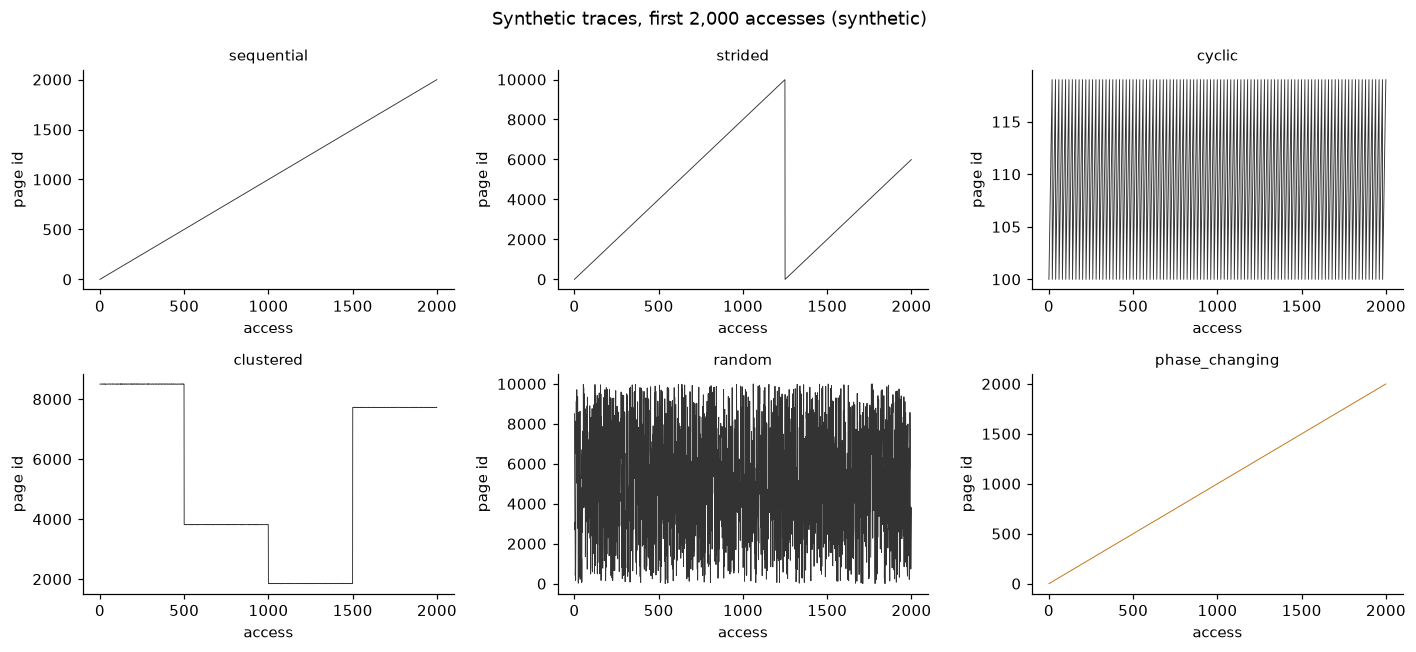

In [4]:
#cell 0b — synthetic trace generators; writes any missing trace to Drive and plots the first accesses
assert 'TRACE_DIR' in globals(), 'Run cell 0a (setup) first'

def sequential(n=50000, start=0, stride=1, n_pages=10000):
    """1, 2, 3, 4 ... — the easiest possible pattern."""
    return [(start + i * stride) % n_pages for i in range(n)]


def strided(n=50000, stride=8, n_pages=10000):
    """0, 8, 16, 24 ... — regular but with gaps."""
    return sequential(n, 0, stride, n_pages)


def cyclic(n=50000, loop_len=20, start=100):
    """A fixed loop repeated forever."""
    loop = [start + i for i in range(loop_len)]
    return [loop[i % loop_len] for i in range(n)]


def clustered(n=50000, cluster_size=10, dwell=500, n_pages=10000, seed=0):
    """Bounces randomly inside a small neighbourhood, then jumps elsewhere."""
    rng = np.random.default_rng(seed)
    trace, i = [], 0
    while i < n:
        base = rng.integers(0, n_pages - cluster_size)
        for _ in range(min(dwell, n - i)):
            trace.append(int(base + rng.integers(0, cluster_size)))
            i += 1
    return trace


def uniform_random(n=50000, n_pages=10000, seed=0):
    """No structure at all — worst case for any predictor."""
    rng = np.random.default_rng(seed)
    return rng.integers(0, n_pages, size=n).tolist()


def phase_changing(n=60000, seed=0):
    """Sequential -> cyclic -> random. Tests the adaptive layer."""
    third = n // 3
    return (sequential(third, start=0, stride=1)
            + cyclic(third, loop_len=25, start=5000)
            + uniform_random(n - 2 * third, seed=seed))


GENERATORS = {'sequential': sequential, 'strided': strided, 'cyclic': cyclic,
              'clustered': clustered, 'random': uniform_random, 'phase_changing': phase_changing}


def write_trace_csv(pages, path):
    os.makedirs(os.path.dirname(path) or '.', exist_ok=True)
    with open(path, 'w', newline='') as f:
        w = csv.writer(f)
        w.writerow(['access_id', 'page_id'])
        w.writerows(enumerate(pages))


for name, fn in GENERATORS.items():
    path = f'{TRACE_DIR}/{name}.csv'
    if os.path.exists(path):
        print(f'{name:15s} already on Drive'); continue
    pages = fn()
    write_trace_csv(pages, path)
    print(f'{name:15s} {len(pages):6d} accesses written')

fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for ax, name in zip(axes.flat, SYNTHETIC):
    p = pd.read_csv(f'{TRACE_DIR}/{name}.csv')['page_id'].values[:2000]
    ax.plot(p, lw=0.6, color=AMBER if name == 'phase_changing' else '#333333')
    ax.set_title(name, fontsize=10); ax.set_xlabel('access'); ax.set_ylabel('page id')
plt.suptitle('Synthetic traces, first 2,000 accesses (synthetic)')
plt.tight_layout(); plt.savefig(f'{FIG}/fig_synthetic_traces.png', dpi=200); plt.show()

### Cell 0c — Stage 1b: real traces (22 ML-DPC LoadTraces)
SPEC CPU 2006 and GAP graph benchmarks from the ML-based Data Prefetching Competition. Use **LoadTraces** (`.txt.xz`,
plain text lines `instr_id, cycle, address, ip, llc_hit`), never ChampSimTraces (binary). Each is converted to 4 KB page
ids, capped at 500,000 accesses.

* Traces already on Drive are skipped. The download goes to the Colab disk first; only the converted CSV is copied to Drive.
* Several minutes per trace. If it disconnects, just re-run: finished traces are skipped.
* `DOWNLOAD_REAL = False` gives a synthetic-only run (every later cell skips what is missing).

In [5]:
#cell 0c — download and convert the real traces (skips any already on Drive)
assert 'TRACE_DIR' in globals(), 'Run cell 0a (setup) first'

DOWNLOAD_REAL = True


def _open(path):
    """Transparently handle .xz, .gz or plain text."""
    if path.endswith('.xz'):
        return lzma.open(path, 'rt')
    if path.endswith('.gz'):
        return gzip.open(path, 'rt')
    return open(path, 'rt')


def convert(in_path, out_path, addr_col=2, is_hex=True, delimiter=',',
            limit=MAX_ACCESSES, page_shift=PAGE_SHIFT):
    """
    Convert an ML-DPC LoadTrace
        (instr_id, cycle, load_addr, ip, llc_hit)
    into access_id,page_id. `addr >> page_shift` maps bytes to 4 KB pages.
    Returns (rows_written, rows_skipped).
    """
    os.makedirs(os.path.dirname(out_path) or '.', exist_ok=True)
    n, skipped = 0, 0
    with _open(in_path) as fin, open(out_path, 'w', newline='') as fout:
        w = csv.writer(fout)
        w.writerow(['access_id', 'page_id'])
        for line in fin:
            parts = line.strip().split(delimiter)
            if len(parts) <= addr_col:
                skipped += 1
                continue
            try:
                addr = int(parts[addr_col].strip(), 16 if is_hex else 10)
            except ValueError:
                skipped += 1
                continue
            w.writerow([n, addr >> page_shift])
            n += 1
            if n >= limit:
                break
    return n, skipped


def parse_download_links(path):
    """Extract {benchmark_name: url} for LoadTraces from ChampSim/download_links."""
    urls = {}
    with open(path) as f:
        for line in f:
            p = line.split()
            if len(p) == 2 and 'LoadTraces' in p[0]:
                urls[p[0].split('/')[-1].replace('.txt.xz', '')] = p[1]
    return urls


missing = [n for n in REAL_ALL if n not in available(REAL_ALL)]
print(f'{len(REAL_ALL) - len(missing)} of {len(REAL_ALL)} real traces already on Drive')
if DOWNLOAD_REAL and missing:
    if not os.path.isdir(CHAMPSIM):                      # the repo holds the list of download links
        subprocess.run(['git', 'clone', '-q', 'https://github.com/Quangmire/ChampSim.git', CHAMPSIM], check=True)
    URLS = parse_download_links(f'{CHAMPSIM}/download_links')
    print(len(URLS), 'LoadTraces listed')
    for name in missing:                                  # one at a time, so each finished trace is saved
        if name not in URLS:
            print(f'{name:18s} not in download_links'); continue
        raw = f'{RAW}/{name}.txt.xz'
        if not os.path.exists(raw):
            print(f'downloading {name} ...', flush=True)
            urllib.request.urlretrieve(URLS[name], raw)
        try:
            with lzma.open(raw, 'rt') as f:
                f.readline()
        except Exception as e:
            print(f'{name}: BAD DOWNLOAD ({e}): Box may have returned an HTML page; delete {raw} and retry')
            continue
        n, skipped = convert(raw, f'{TRACE_DIR}/{name}.csv')
        print(f'{name:18s} {os.path.getsize(raw) / 1e6:6.0f} MB -> {n} accesses, {skipped} skipped')
        os.remove(raw)

have = available(REAL_ALL)
print(f'\nreal traces available: {len(have)} / {len(REAL_ALL)}')
if len(have) < len(REAL_ALL):
    print('missing (results for these are skipped):', [n for n in REAL_ALL if n not in have])

22 of 22 real traces already on Drive

real traces available: 22 / 22


### Cell 0d — trace characterisation
How regular is each workload? `reuse` = accesses per distinct page; `top5_share` = share of steps covered by the five most
common page deltas (high = predictable, stride-like structure). Measured on the first 200,000 accesses, as in the experiments.

,trace,type,accesses,unique_pages,reuse,unique_deltas,top_delta,top_delta_share,top5_share
0,sequential,synthetic,50000,10000,5.00,2,1,1.000,1.000
1,strided,synthetic,50000,1250,40.00,2,8,0.999,1.000
2,cyclic,synthetic,50000,20,2500.00,2,1,0.950,1.000
3,clustered,synthetic,50000,908,55.07,118,0,0.100,0.440
4,random,synthetic,50000,9930,5.04,16078,-1083,0.000,0.001
5,phase_changing,synthetic,60000,10000,6.00,11413,1,0.653,0.667
6,410.bwaves-s0,real,200000,3051,65.55,2845,1,0.674,0.797
7,410.bwaves-s1,real,200000,3050,65.57,3137,1,0.667,0.793
8,410.bwaves-s2,real,17547,274,64.04,542,0,0.876,0.910
9,437.leslie3d-s0,real,200000,2134,93.72,3161,0,0.248,0.555


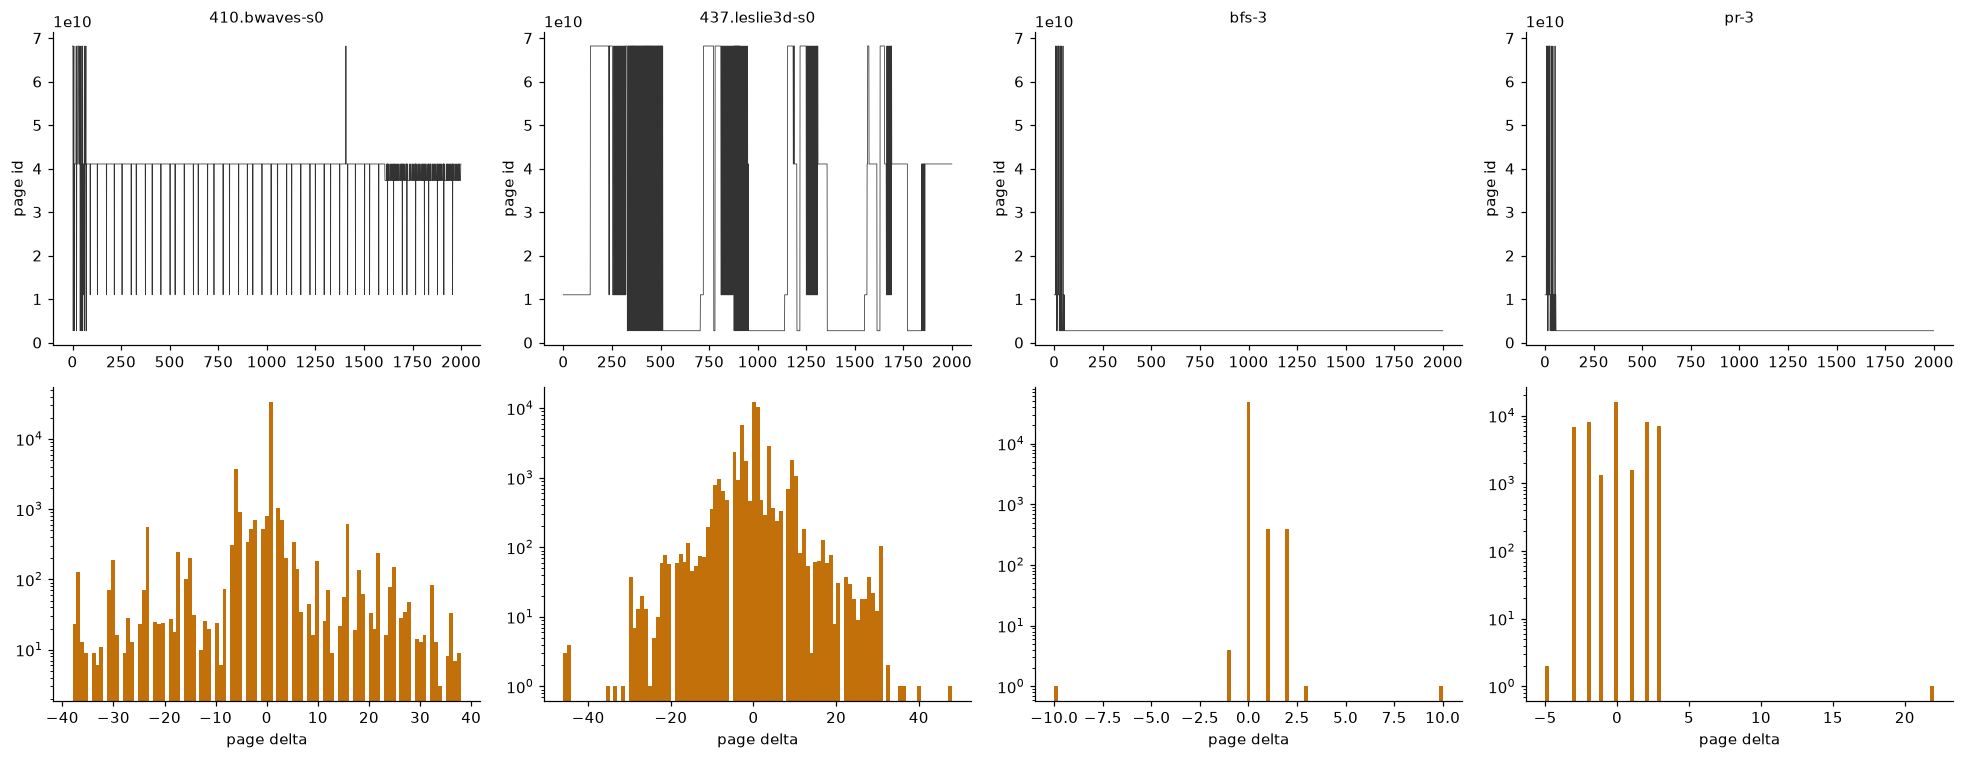

In [6]:
#cell 0d — characterise every available trace, and plot the original four
assert 'TRACE_DIR' in globals(), 'Run cell 0a (setup) first'

rows = []
for name in available(SYNTHETIC + REAL_ALL):
    p = pd.read_csv(f'{TRACE_DIR}/{name}.csv')['page_id'].values[:TRACE_LIMIT]
    d = np.diff(p); vc = pd.Series(d).value_counts()
    rows.append({'trace': name, 'type': 'synthetic' if name in SYNTHETIC else 'real',
                 'accesses': len(p), 'unique_pages': len(np.unique(p)),
                 'reuse': round(len(p) / len(np.unique(p)), 2), 'unique_deltas': len(vc),
                 'top_delta': int(vc.index[0]), 'top_delta_share': round(vc.iloc[0] / len(d), 3),
                 'top5_share': round(vc.iloc[:5].sum() / len(d), 3)})
chars = pd.DataFrame(rows)
chars.to_csv(f'{RESULTS}/trace_characteristics.csv', index=False)
display(chars)

real4 = available(PICK)
if real4:
    fig, axes = plt.subplots(2, len(real4), figsize=(4.5 * len(real4), 7), squeeze=False)
    for i, name in enumerate(real4):
        p = pd.read_csv(f'{TRACE_DIR}/{name}.csv')['page_id'].values
        axes[0, i].plot(p[:2000], lw=0.5, color='#333333')
        axes[0, i].set_title(name, fontsize=10); axes[0, i].set_ylabel('page id')
        d = np.diff(p[:50000]); d = d[np.abs(d) < 50]
        axes[1, i].hist(d, bins=101, color=AMBER)
        axes[1, i].set_xlabel('page delta'); axes[1, i].set_yscale('log')
    plt.tight_layout(); plt.savefig(f'{FIG}/fig_real_traces.png', dpi=200); plt.show()

### Cell 0e — Stage 2: the normalised `Trace` object
Every trace, synthetic or real, becomes the same object. `train` is the 25% warm-up portion (the only data any setting may
be tuned on); `test` is the rest. `stream()` yields accesses one at a time, with no lookahead.

In [7]:
#cell 0e — Trace class, loader and checks
assert 'TRACE_DIR' in globals(), 'Run cell 0a (setup) first'

class Trace:
    """One workload, normalised. Knows nothing about where it came from."""

    def __init__(self, name, pages, train_frac=0.25):
        self.name = name
        self.pages = np.asarray(pages, dtype=np.int64)
        self.deltas = np.diff(self.pages, prepend=self.pages[0])
        self.split = int(len(self.pages) * train_frac)

    @property
    def train(self):
        """Warm-up portion. Model MAY learn from this."""
        return self.pages[:self.split]

    @property
    def test(self):
        """Evaluation portion. Metrics measured ONLY here."""
        return self.pages[self.split:]

    def stream(self, portion='all'):
        """Yield (index, page, delta) one at a time. No lookahead."""
        src = {'all':   (0, len(self.pages)),
               'train': (0, self.split),
               'test':  (self.split, len(self.pages))}[portion]
        for i in range(*src):
            yield i, int(self.pages[i]), int(self.deltas[i])

    def __len__(self):
        return len(self.pages)

    def __repr__(self):
        return (f'<Trace {self.name}: {len(self)} accesses, '
                f'{len(np.unique(self.pages))} unique pages, split@{self.split}>')


def load_trace(name, trace_dir=None, limit=None, train_frac=WARMUP_FRAC):
    df = pd.read_csv(f'{trace_dir or TRACE_DIR}/{name}.csv')
    pages = df['page_id'].values
    if limit:
        pages = pages[:limit]
    return Trace(name, pages, train_frac)


t = load_trace(available(SYNTHETIC + REAL_ALL)[0], limit=50_000)
print(t)
assert len(t.pages) == len(t.deltas), 'delta/page length mismatch'
assert len(t.train) + len(t.test) == len(t), 'split loses accesses'
assert np.array_equal(np.concatenate([t.train, t.test]), t.pages), 'split reordered the sequence'
assert np.array_equal(np.cumsum(t.deltas) + t.pages[0] - t.deltas[0], t.pages), 'deltas inconsistent'
assert [p for _, p, _ in t.stream()] == t.pages.tolist(), 'stream != pages'
print(f'train: {len(t.train)}  test: {len(t.test)}')
print('first 10 pages :', t.pages[:10].tolist())
print('first 10 deltas:', t.deltas[:10].tolist())
print('all checks passed')

<Trace sequential: 50000 accesses, 10000 unique pages, split@12500>
train: 12500  test: 37500
first 10 pages : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
first 10 deltas: [0, 1, 1, 1, 1, 1, 1, 1, 1, 1]
all checks passed


## Stage 3: prediction
### Cell 1 — the predictors
* **Markov**: a bounded table `context -> {next page: count}` (LRU-evicted contexts, top-K successors, counts halved periodically).
* **Stride**: next = last + stride when the last three steps agree.
* **Hybrid**: order-2 Markov first, then order-1, then stride. Every table learns on every access.

Every predictor implements `predict(history, top_n)`, `update(history, actual_next)`, `stats()`.

In [8]:
#cell 1 — Markov, stride and hybrid predictors
assert 'TRACE_DIR' in globals(), 'Run cell 0a (setup) first'

class MarkovPredictor:
    """Counts observed transitions. Bounded LRU table, top-K successors."""

    def __init__(self, capacity=256, max_succ=2, order=2,
                 decay_every=25_000, min_count=1, smooth=0.0):
        self.smooth = smooth             # confidence = count / (total + smooth); 0 = original
        self.capacity = capacity
        self.max_succ = max_succ
        self.order = order
        self.decay_every = decay_every
        self.min_count = min_count
        self.table = OrderedDict()      # context -> {successor: count}
        self.n_updates = 0
        self.evictions = 0

    def _key(self, history):
        if len(history) < self.order:
            return None
        return tuple(history[-self.order:])

    def update(self, history, actual_next):
        k = self._key(history)
        if k is None:
            return
        if k in self.table:
            self.table.move_to_end(k)
        else:
            if len(self.table) >= self.capacity:
                self.table.popitem(last=False)
                self.evictions += 1
            self.table[k] = {}

        succ = self.table[k]
        succ[actual_next] = succ.get(actual_next, 0) + 1
        if len(succ) > self.max_succ:
            del succ[min(succ, key=succ.get)]

        self.n_updates += 1
        if self.n_updates % self.decay_every == 0:
            self._decay()

    def _decay(self):
        for succ in self.table.values():
            for s in list(succ):
                succ[s] >>= 1
                if succ[s] == 0:
                    del succ[s]

    def predict(self, history, top_n=1):
        k = self._key(history)
        if k is None or k not in self.table:
            return []
        succ = self.table[k]
        total = sum(succ.values())
        if total == 0:
            return []
        ranked = sorted(succ.items(), key=lambda kv: -kv[1])[:top_n]
        return [(p, c / (total + self.smooth)) for p, c in ranked if c >= self.min_count]

    def stats(self):
        return {'entries': len(self.table), 'evictions': self.evictions,
                'fill': round(len(self.table) / self.capacity, 3)}


class StridePredictor:
    """Predicts next = last + stride when recent deltas agree."""

    def __init__(self, confirm=3):
        self.confirm = confirm

    def predict(self, history, top_n=1):
        if len(history) < self.confirm + 1:
            return []
        d = [history[i] - history[i - 1] for i in range(-self.confirm, 0)]
        if len(set(d)) != 1 or d[0] == 0:
            return []
        return [(history[-1] + d[0], 1.0)]

    def update(self, history, actual_next):
        pass

    def stats(self):
        return {}


class HybridPredictor:
    """Order-2 Markov first (precise), order-1 fallback (broad), then stride."""

    def __init__(self, capacity=256, max_succ=2, decay_every=25_000):
        self.m2 = MarkovPredictor(capacity, max_succ, order=2, decay_every=decay_every)
        self.m1 = MarkovPredictor(capacity, max_succ, order=1, decay_every=decay_every)
        self.st = StridePredictor()
        self.source_counts = {'m2': 0, 'm1': 0, 'stride': 0, 'none': 0}

    def predict(self, history, top_n=1):
        for tag, p in (('m2', self.m2), ('m1', self.m1), ('stride', self.st)):
            r = p.predict(history, top_n)
            if r:
                self.source_counts[tag] += 1
                return r
        self.source_counts['none'] += 1
        return []

    def update(self, history, actual_next):
        self.m2.update(history, actual_next)
        self.m1.update(history, actual_next)

    def stats(self):
        return {'sources': dict(self.source_counts), **self.m2.stats()}


print('predictors ready')

predictors ready


### Cell 2 — how prediction quality is measured
Learns online over the whole trace, but measures only after the 25% warm-up. `coverage` = share of accesses with a
prediction; `accuracy` = share of predictions that were right; `useful = coverage × accuracy`.

In [9]:
#cell 2 — eval_predictor
assert 'TRACE_DIR' in globals(), 'Run cell 0a (setup) first'

def eval_predictor(trace, predictor, warmup_frac=0.25, hist_len=8):
    """Stream the trace; learn throughout, measure only past warm-up."""
    pages = trace.pages
    split = int(len(pages) * warmup_frac)
    history = []
    attempted = correct = 0
    conf_sum = 0.0

    for i in range(len(pages) - 1):
        history.append(int(pages[i]))
        if len(history) > hist_len:
            history.pop(0)
        actual = int(pages[i + 1])

        if i >= split:
            preds = predictor.predict(history, top_n=1)
            if preds:
                page, conf = preds[0]
                attempted += 1
                conf_sum += conf
                if page == actual:
                    correct += 1

        predictor.update(history, actual)     # online learning throughout

    n_eval = max(1, len(pages) - 1 - split)
    coverage = attempted / n_eval
    accuracy = correct / attempted if attempted else 0.0
    return {'coverage': coverage, 'accuracy': accuracy,
            'useful': coverage * accuracy,
            'mean_conf': conf_sum / attempted if attempted else 0.0,
            'extra': predictor.stats()}


print('eval_predictor ready')

eval_predictor ready


### Cell 3 — load the Stage 3-5 traces
The six synthetic traces plus the original four real ones, first 200,000 accesses each.

In [10]:
#cell 3 — TRACES: the traces used in Stages 3-5, as Trace objects
assert 'TRACE_DIR' in globals(), 'Run cell 0a (setup) first'

TRACES = {n: load_trace(n, limit=TRACE_LIMIT) for n in available(SYNTHETIC + PICK)}
REAL = [n for n in PICK if n in TRACES]
assert all(hasattr(t, 'pages') for t in TRACES.values()), 'TRACES holds raw lists'
print(f'{len(TRACES)} traces loaded ({len(REAL)} real):')
for t in TRACES.values():
    print('  ', t)
if not REAL:
    print('NOTE: no real traces: every result below is SYNTHETIC ONLY and must be labelled so')

10 traces loaded (4 real):
   <Trace sequential: 50000 accesses, 10000 unique pages, split@12500>
   <Trace strided: 50000 accesses, 1250 unique pages, split@12500>
   <Trace cyclic: 50000 accesses, 20 unique pages, split@12500>
   <Trace clustered: 50000 accesses, 908 unique pages, split@12500>
   <Trace random: 50000 accesses, 9930 unique pages, split@12500>
   <Trace phase_changing: 60000 accesses, 10000 unique pages, split@15000>
   <Trace 410.bwaves-s0: 200000 accesses, 3051 unique pages, split@50000>
   <Trace 437.leslie3d-s0: 200000 accesses, 2134 unique pages, split@50000>
   <Trace bfs-3: 200000 accesses, 5846 unique pages, split@50000>
   <Trace pr-3: 200000 accesses, 4062 unique pages, split@50000>


### Cell 4 — frozen hyperparameters
Chosen once from the sweeps below and then frozen: **never tuned on evaluation data**. `make_predictor` is the single
place that builds predictors (the `delta-hybrid` kind is defined in cell 22).

In [11]:
#cell 4 — FROZEN hyperparameters and the predictor factory
assert 'TRACE_DIR' in globals(), 'Run cell 0a (setup) first'

FROZEN = dict(capacity=256, max_succ=2, order=2, decay_every=25_000)
#   capacity=256  -> useful_real flat (0.783) from 256 to 4096 entries; 8.5 KB table
#   max_succ=2    -> 2 / 4 / 8 successors differ by < 0.0002; take the cheapest
#   order=2       -> beats order-1 by ~4.5 points
#   decay=25000   -> marginally best

KINDS = ['stride', 'markov-o1', 'markov-o2', 'hybrid']


def make_predictor(kind, cfg=None):
    """Single place that constructs predictors, always from the frozen config."""
    cfg = cfg or FROZEN
    if kind == 'stride':
        return StridePredictor()
    if kind == 'markov-o1':
        return MarkovPredictor(**{**cfg, 'order': 1})
    if kind == 'markov-o2':
        return MarkovPredictor(**cfg)
    if kind == 'delta-hybrid':
        return DeltaHybridPredictor(capacity=cfg['capacity'], max_succ=cfg['max_succ'],
                                    decay_every=cfg['decay_every'])
    if kind == 'hybrid':
        return HybridPredictor(capacity=cfg['capacity'], max_succ=cfg['max_succ'],
                               decay_every=cfg['decay_every'])
    raise ValueError(kind)


print('FROZEN =', FROZEN)

FROZEN = {'capacity': 256, 'max_succ': 2, 'order': 2, 'decay_every': 25000}


### Cell 5 — prediction quality on every trace
What to look for: Markov is ~0 on `sequential`/`strided` (their working sets are larger than the 256-entry table; stride
covers them), nothing predicts `random`, and the hybrid is the best or tied everywhere.

In [12]:
#cell 5 — coverage / accuracy / useful for every predictor and trace
assert 'TRACE_DIR' in globals(), 'Run cell 0a (setup) first'
assert 'TRACES' in globals() and 'make_predictor' in globals(), 'run cells 1-4 first'

rows = []
for name, t in TRACES.items():
    for k in KINDS:
        s = eval_predictor(t, make_predictor(k))
        rows.append({'trace': name, 'type': 'real' if name in REAL else 'synthetic', 'predictor': k,
                     'coverage': round(s['coverage'], 3), 'accuracy': round(s['accuracy'], 3),
                     'useful': round(s['useful'], 3)})
results = pd.DataFrame(rows)
results.to_csv(f'{RESULTS}/predictor_results.csv', index=False)

for metric in ('coverage', 'accuracy'):
    print(f'\n===== {metric.upper()} =====')
    display(results.pivot(index='trace', columns='predictor', values=metric)[KINDS])
print('\n===== USEFUL = coverage x accuracy =====')
useful = results.pivot(index='trace', columns='predictor', values='useful')[KINDS]
try:                                     # coloured table (needs jinja2, which Colab has)
    display(useful.style.background_gradient(cmap=CMAP, axis=None, vmin=0, vmax=1).format('{:.3f}'))
except (AttributeError, ImportError):
    display(useful)
h = results[results.predictor == 'hybrid']
print(f"hybrid mean useful: real {h[h.type == 'real'].useful.mean():.4f}   all {h.useful.mean():.4f}")


===== COVERAGE =====


predictor,stride,markov-o1,markov-o2,hybrid
trace,,,,
410.bwaves-s0,0.367,0.984,0.908,0.991
437.leslie3d-s0,0.038,0.984,0.926,0.984
bfs-3,0.000,0.963,0.850,0.963
clustered,0.002,0.981,0.799,0.982
cyclic,0.850,1.000,1.000,1.000
phase_changing,0.502,0.455,0.444,0.567
pr-3,0.000,0.970,0.927,0.970
random,0.000,0.025,0.000,0.025
sequential,1.000,0.000,0.000,1.000



===== ACCURACY =====


predictor,stride,markov-o1,markov-o2,hybrid
trace,,,,
410.bwaves-s0,0.697,0.800,0.838,0.811
437.leslie3d-s0,0.044,0.857,0.882,0.857
bfs-3,0.000,0.695,0.792,0.732
clustered,0.032,0.098,0.101,0.101
cyclic,0.941,1.000,1.000,1.000
phase_changing,0.965,0.976,1.000,0.980
pr-3,0.324,0.473,0.950,0.919
random,0.000,0.000,0.000,0.000
sequential,1.000,0.000,0.000,1.000



===== USEFUL = coverage x accuracy =====


predictor,stride,markov-o1,markov-o2,hybrid
trace,,,,
410.bwaves-s0,0.256,0.788,0.761,0.804
437.leslie3d-s0,0.002,0.843,0.816,0.844
bfs-3,0.000,0.669,0.673,0.706
clustered,0.000,0.097,0.081,0.099
cyclic,0.800,1.000,1.000,1.000
phase_changing,0.484,0.444,0.444,0.555
pr-3,0.000,0.458,0.881,0.892
random,0.000,0.000,0.000,0.000
sequential,1.000,0.000,0.000,1.000


hybrid mean useful: real 0.8115   all 0.6897


### Cell 6 — which part of the hybrid answered?
Share of predictions made by each tier (`none` = no tier had a prediction).

,m2,m1,stride,none
trace,,,,
sequential,0.000,0.000,1.000,0.000
strided,0.000,0.000,0.998,0.002
cyclic,1.000,0.000,0.000,0.000
clustered,0.799,0.182,0.000,0.018
random,0.000,0.025,0.000,0.975
phase_changing,0.444,0.011,0.112,0.433
410.bwaves-s0,0.908,0.076,0.006,0.009
437.leslie3d-s0,0.926,0.058,0.001,0.016
bfs-3,0.850,0.113,0.000,0.037


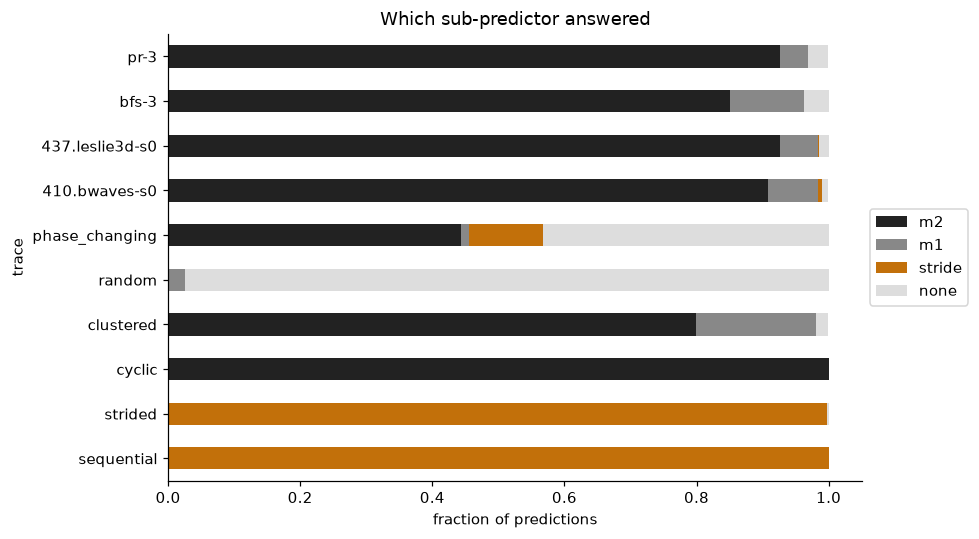

In [13]:
#cell 6 — attribution of the hybrid's predictions
assert 'TRACE_DIR' in globals(), 'Run cell 0a (setup) first'

attrib = []
for name, t in TRACES.items():
    h = make_predictor('hybrid')
    eval_predictor(t, h)
    src = h.stats()['sources']; tot = max(1, sum(src.values()))
    attrib.append({'trace': name, **{k: round(v / tot, 3) for k, v in src.items()}})
att = pd.DataFrame(attrib).set_index('trace')
att.to_csv(f'{RESULTS}/predictor_attribution.csv')
display(att)

att[['m2', 'm1', 'stride', 'none']].plot(kind='barh', stacked=True, figsize=(9, 5),
                                         color=['#222222', '#888888', AMBER, '#dddddd'])
plt.xlabel('fraction of predictions'); plt.title('Which sub-predictor answered')
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5)); plt.tight_layout()
plt.savefig(f'{FIG}/fig_attribution.png', dpi=200); plt.show()

### Cell 7 — memory footprint of the order-2 table
Information-theoretic size (8-byte page numbers, 9 bytes per successor), not Python overhead. The full hybrid also has an
order-1 table (~6.5 KB more), so ~15 KB in total.

In [14]:
#cell 7 — table footprint and overhead as a share of simulated RAM
assert 'TRACE_DIR' in globals(), 'Run cell 0a (setup) first'

CTX_BYTES  = FROZEN['order'] * 8    # 64-bit page numbers
SUCC_BYTES = 9                      # 8 B page + 1 B saturating counter
MAX_BYTES  = FROZEN['capacity'] * CTX_BYTES + FROZEN['capacity'] * FROZEN['max_succ'] * SUCC_BYTES

foot = []
for name, t in TRACES.items():
    m = MarkovPredictor(**FROZEN)
    eval_predictor(t, m)
    n_ctx = len(m.table); n_succ = sum(len(s) for s in m.table.values())
    raw_b = n_ctx * CTX_BYTES + n_succ * SUCC_BYTES
    foot.append({'trace': name, 'contexts': n_ctx, 'successors': n_succ, 'evictions': m.evictions,
                 'table_KB': round(raw_b / 1024, 1), 'pct_of_max': round(100 * raw_b / MAX_BYTES, 1)})
fp = pd.DataFrame(foot)
fp.to_csv(f'{RESULTS}/memory_footprint.csv', index=False)
display(fp)
print(f"bounded ceiling: {MAX_BYTES / 1024:.1f} KB (~{MAX_BYTES / 4096:.1f} pages); observed max {fp.table_KB.max():.1f} KB")
for frames in (128, 256, 512, 1024):
    print(f'  overhead at {frames:5d} frames: {100 * MAX_BYTES / 1024 / (frames * 4):.2f}% of RAM')

,trace,contexts,successors,evictions,table_KB,pct_of_max
0,sequential,256,256,49742,6.2,73.5
1,strided,256,256,49742,6.2,73.5
2,cyclic,20,20,0,0.5,5.7
3,clustered,256,500,9768,8.4,98.8
4,random,256,256,49742,6.2,73.5
5,phase_changing,256,256,39768,6.2,73.5
6,410.bwaves-s0,256,340,18074,7.0,82.2
7,437.leslie3d-s0,256,339,14640,7.0,82.1
8,bfs-3,256,363,23820,7.2,84.6
9,pr-3,256,282,13289,6.5,76.2


bounded ceiling: 8.5 KB (~2.1 pages); observed max 8.4 KB
  overhead at   128 frames: 1.66% of RAM
  overhead at   256 frames: 0.83% of RAM
  overhead at   512 frames: 0.42% of RAM
  overhead at  1024 frames: 0.21% of RAM


### Cell 8 — capacity sweep
Does a bigger table predict better? On the real traces `useful` is flat from 128 entries up, while the table grows 32×:
that is why capacity was frozen at 256.

,capacity,table_KB,useful_real,useful_all
0,128,4.2,0.783,0.466
1,256,8.5,0.783,0.466
2,512,17.0,0.783,0.466
3,1024,34.0,0.783,0.466
4,2048,68.0,0.783,0.566
5,4096,136.0,0.783,0.566


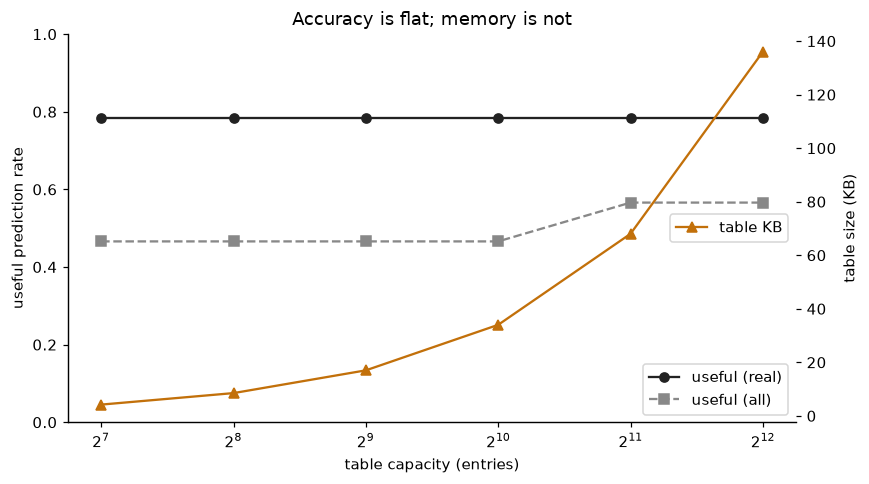

In [15]:
#cell 8 — table capacity vs usefulness vs size (order-2 Markov)
assert 'TRACE_DIR' in globals(), 'Run cell 0a (setup) first'

rows = []
for cap in (128, 256, 512, 1024, 2048, 4096):
    cfg = {**FROZEN, 'capacity': cap}
    real_s, all_s = [], []
    for name, t in TRACES.items():
        u = eval_predictor(t, MarkovPredictor(**cfg))['useful']
        all_s.append(u)
        if name in REAL:
            real_s.append(u)
    rows.append({'capacity': cap, 'table_KB': round((cap * CTX_BYTES + cap * cfg['max_succ'] * SUCC_BYTES) / 1024, 1),
                 'useful_real': round(np.mean(real_s), 3) if real_s else None, 'useful_all': round(np.mean(all_s), 3)})
sw = pd.DataFrame(rows)
sw.to_csv(f'{RESULTS}/capacity_sweep.csv', index=False)
display(sw)

fig, ax1 = plt.subplots(figsize=(8, 4.5))
if sw.useful_real.notna().any():
    ax1.plot(sw.capacity, sw.useful_real, 'o-', color='#222222', label='useful (real)')
ax1.plot(sw.capacity, sw.useful_all, 's--', color='#888888', label='useful (all)')
ax1.set_xscale('log', base=2); ax1.set_xlabel('table capacity (entries)')
ax1.set_ylabel('useful prediction rate'); ax1.set_ylim(0, 1)
ax2 = ax1.twinx(); ax2.plot(sw.capacity, sw.table_KB, '^-', color=AMBER, label='table KB')
ax2.set_ylabel('table size (KB)')
ax1.legend(loc='lower right'); ax2.legend(loc='center right')
plt.title('Accuracy is flat; memory is not'); plt.tight_layout()
plt.savefig(f'{FIG}/fig_capacity_sweep.png', dpi=200); plt.show()

### Cell 9 — adaptation across workload phases (synthetic)
Rolling accuracy on `phase_changing` (sequential → cyclic → random), and how many accesses each predictor needs to recover
after a phase change. The hybrid should hold the best tier in each phase.

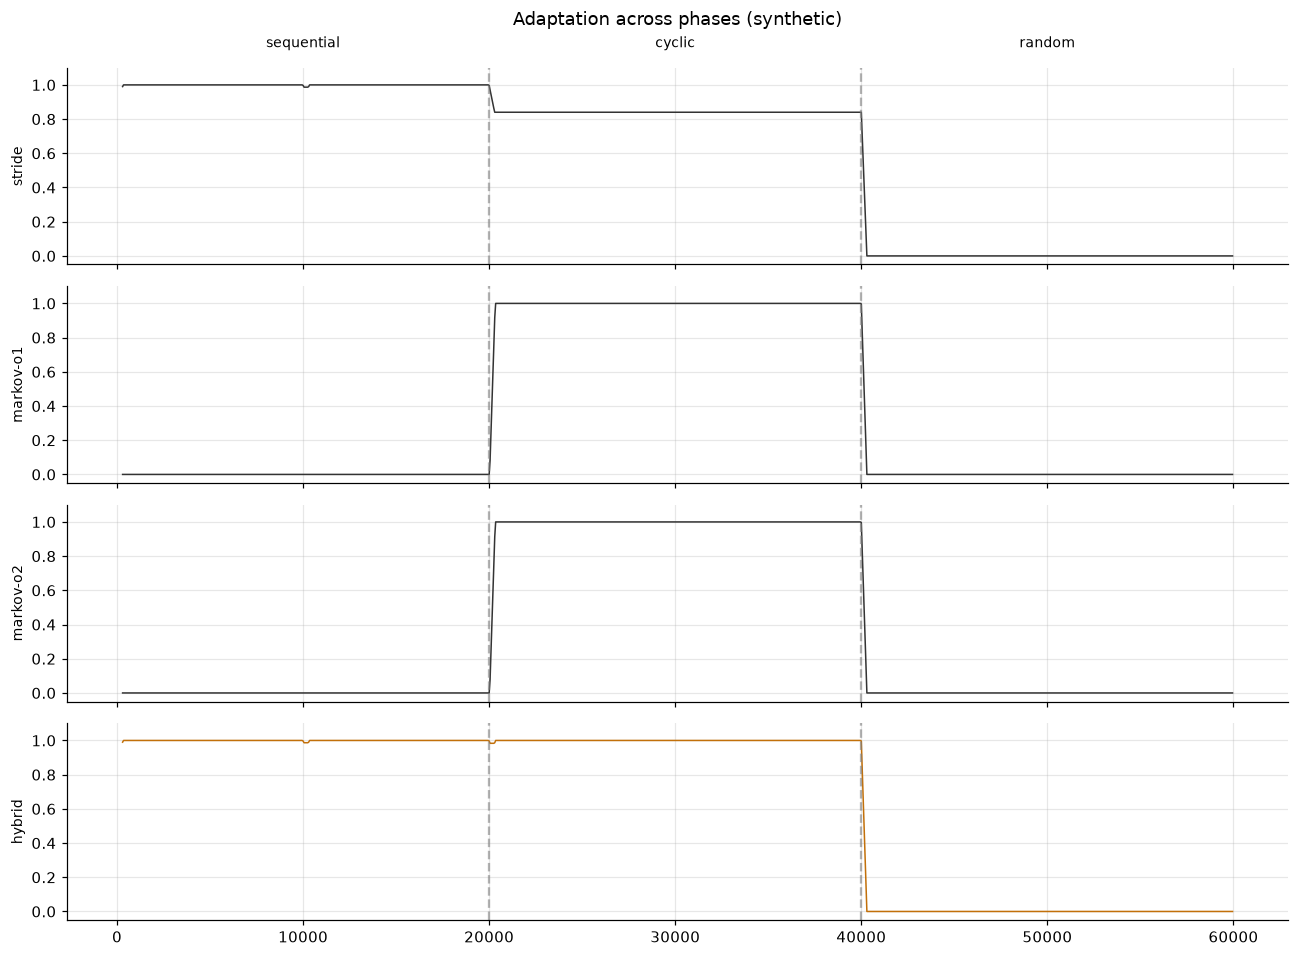

accesses needed to reach 90% of the post-transition plateau:


,predictor,seq -> cyclic,cyclic -> random
0,stride,9,9
1,markov-o1,69,9
2,markov-o2,79,9
3,hybrid,9,9


In [16]:
#cell 9 — rolling accuracy on phase_changing, and recovery times
assert 'TRACE_DIR' in globals(), 'Run cell 0a (setup) first'

def rolling_accuracy(trace, predictor, window=300, warmup_frac=0.0,
                     hist_len=8, step=50):
    pages = trace.pages
    split = int(len(pages) * warmup_frac)
    hist, hits, xs, ys = [], [], [], []
    for i in range(len(pages) - 1):
        hist.append(int(pages[i]))
        if len(hist) > hist_len:
            hist.pop(0)
        actual = int(pages[i + 1])
        if i >= split:
            p = predictor.predict(hist, top_n=1)
            hits.append(1 if (p and p[0][0] == actual) else 0)
            if len(hits) >= window and len(hits) % step == 0:
                xs.append(i)
                ys.append(float(np.mean(hits[-window:])))
        predictor.update(hist, actual)
    return xs, ys


if 'phase_changing' in TRACES:
    t = TRACES['phase_changing']; n = len(t.pages); b1, b2 = n // 3, 2 * n // 3
    fig, axes = plt.subplots(len(KINDS), 1, figsize=(12, 2.2 * len(KINDS)), sharex=True, sharey=True)
    for ax, k in zip(axes, KINDS):
        xs, ys = rolling_accuracy(t, make_predictor(k))
        ax.plot(xs, ys, lw=1.0, color=AMBER if k == 'hybrid' else '#333333')
        for b in (b1, b2):
            ax.axvline(b, ls='--', c='grey', alpha=.6)
        ax.set_ylim(-.05, 1.1); ax.set_ylabel(k, fontsize=9); ax.grid(alpha=.3)
    axes[0].set_title('Adaptation across phases (synthetic)', pad=28)
    for x, label in ((b1 / 2, 'sequential'), ((b1 + b2) / 2, 'cyclic'), ((b2 + n) / 2, 'random')):
        axes[0].text(x, 1.22, label, ha='center', fontsize=9)
    plt.tight_layout(); plt.savefig(f'{FIG}/fig_phase_adaptation.png', dpi=200, bbox_inches='tight'); plt.show()

    def recovery_time(trace, predictor, boundary, window=50, step=10, target=0.9, lookahead=5000):
        xs, ys = rolling_accuracy(trace, predictor, window=window, step=step)
        post = [(x, y) for x, y in zip(xs, ys) if boundary <= x <= boundary + lookahead]
        if not post:
            return None
        plateau = max(y for _, y in post)
        if plateau <= 0:
            return 0
        return next((x - boundary for x, y in post if y >= target * plateau), None)

    rec = pd.DataFrame([{'predictor': k, 'seq -> cyclic': recovery_time(t, make_predictor(k), b1),
                         'cyclic -> random': recovery_time(t, make_predictor(k), b2)} for k in KINDS])
    print('accesses needed to reach 90% of the post-transition plateau:')
    display(rec)
else:
    print('phase_changing trace missing: run cell 0b')

### Cell 10 — Stage 3 summary

In [17]:
#cell 10 — save the Stage 3 summary
assert 'TRACE_DIR' in globals(), 'Run cell 0a (setup) first'

summary = {'frozen_config': FROZEN, 'n_traces': len(TRACES), 'real_traces': REAL, 'synthetic': SYNTHETIC,
           'table_KB': round(MAX_BYTES / 1024, 1),
           'hybrid_mean_useful_real': float(results[(results.predictor == 'hybrid') & (results.type == 'real')].useful.mean())
                                      if REAL else None,
           'hybrid_mean_useful_all': float(results[results.predictor == 'hybrid'].useful.mean())}
with open(f'{RESULTS}/stage3_summary.json', 'w') as f:
    json.dump(summary, f, indent=2, default=str)
print(json.dumps(summary, indent=2, default=str))

{
  "frozen_config": {
    "capacity": 256,
    "max_succ": 2,
    "order": 2,
    "decay_every": 25000
  },
  "n_traces": 10,
  "real_traces": [
    "410.bwaves-s0",
    "437.leslie3d-s0",
    "bfs-3",
    "pr-3"
  ],
  "synthetic": [
    "sequential",
    "strided",
    "cyclic",
    "clustered",
    "random",
    "phase_changing"
  ],
  "table_KB": 8.5,
  "hybrid_mean_useful_real": 0.8115,
  "hybrid_mean_useful_all": 0.6897000000000001
}


## Stage 4: memory engine and eviction policies
### Cell 11 — the memory engine
Page table + frame table + fault handler; it knows nothing about policy. **Architectural rule: `_install()` is the only
path into RAM.** A prefetch goes through it exactly like a demand fault, so a broken predictor can make the system slow,
never wrong.

In [18]:
#cell 11 — MemoryEngine
assert 'TRACE_DIR' in globals(), 'Run cell 0a (setup) first'

class MemoryEngine:
    """Page table + frame table + fault handler. Knows nothing about policy."""

    def __init__(self, n_frames, policy):
        self.n_frames = n_frames
        self.policy = policy
        self.resident = set()
        self.log = None            # optional event list for the time model (Phase 15): ('F'|'P'|'U', i, page)
        self.reset_stats()

    def reset_stats(self):
        self.n_access = 0
        self.n_fault = 0
        self.n_evict = 0
        self.prefetched = {}       # page -> still-unused flag
        self.n_prefetch = 0
        self.n_pf_used = 0
        self.n_pf_wasted = 0

    def _install(self, page, i, is_prefetch=False):
        if page in self.resident:
            return
        if len(self.resident) >= self.n_frames:
            victim = self.policy.choose_victim(self.resident, i)
            self.resident.discard(victim)
            self.policy.on_evict(victim)
            self.n_evict += 1
            if self.prefetched.pop(victim, False):
                self.n_pf_wasted += 1
        self.resident.add(page)
        self.policy.on_insert(page, i)
        if is_prefetch:
            self.prefetched[page] = True
            self.n_prefetch += 1
            mark = getattr(self.policy, 'mark_prefetch', None)    # optional hook (Phase 9)
            if mark is not None:
                mark(page, i)

    def access(self, page, i):
        """Demand access. Returns True if it was a fault."""
        self.n_access += 1
        hit = page in self.resident
        if self.prefetched.pop(page, False):
            self.n_pf_used += 1
            if self.log is not None:
                self.log.append(('U', i, page))
        if hit:
            self.policy.on_hit(page, i)
            return False
        self.n_fault += 1
        if self.log is not None:
            self.log.append(('F', i, page))
        self._install(page, i, is_prefetch=False)
        return True

    def prefetch(self, page, i):
        """Speculative load. Never bypasses the fault handler."""
        if page in self.resident:
            return False
        if self.log is not None:
            self.log.append(('P', i, page))
        self._install(page, i, is_prefetch=True)
        return True

    def stats(self):
        return {
            'accesses':     self.n_access,
            'faults':       self.n_fault,
            'fault_rate':   self.n_fault / max(1, self.n_access),
            'evictions':    self.n_evict,
            'prefetches':   self.n_prefetch,
            'pf_used':      self.n_pf_used,
            'pf_wasted':    self.n_pf_wasted,
            'pf_precision': self.n_pf_used / max(1, self.n_prefetch),
        }


print('MemoryEngine ready')

MemoryEngine ready


### Cell 12 — FIFO, LRU and Clock
Every policy implements `on_insert`, `on_hit`, `on_evict`, `choose_victim`, and takes `pages=` in its constructor.

In [19]:
#cell 12 — eviction policies
assert 'TRACE_DIR' in globals(), 'Run cell 0a (setup) first'

class FIFO:
    def __init__(self, **kw):
        self.q = deque()

    def on_insert(self, page, i): self.q.append(page)
    def on_hit(self, page, i): pass
    def on_evict(self, page): pass

    def choose_victim(self, resident, i):
        while self.q:
            p = self.q.popleft()
            if p in resident:
                return p
        return next(iter(resident))


class LRU:
    def __init__(self, **kw):
        self.od = OrderedDict()

    def on_insert(self, page, i):
        self.od[page] = i
        self.od.move_to_end(page)

    def on_hit(self, page, i):
        self.od[page] = i
        self.od.move_to_end(page)

    def on_evict(self, page):
        self.od.pop(page, None)

    def choose_victim(self, resident, i):
        for p in self.od:
            if p in resident:
                return p
        return next(iter(resident))


class Clock:
    """Second-chance approximation of LRU."""

    def __init__(self, **kw):
        self.ring, self.ref, self.hand = [], {}, 0

    def on_insert(self, page, i):
        self.ring.append(page)
        self.ref[page] = 1

    def on_hit(self, page, i):
        self.ref[page] = 1

    def on_evict(self, page):
        if page in self.ring:
            idx = self.ring.index(page)
            self.ring.pop(idx)
            self.ref.pop(page, None)
            if self.hand > idx:
                self.hand -= 1

    def choose_victim(self, resident, i):
        while True:
            if not self.ring:
                return next(iter(resident))
            self.hand %= len(self.ring)
            p = self.ring[self.hand]
            if p not in resident:
                self.ring.pop(self.hand)
                self.ref.pop(p, None)
                continue
            if self.ref.get(p, 0) == 0:
                return p
            self.ref[p] = 0
            self.hand += 1


print('FIFO, LRU, Clock ready')

FIFO, LRU, Clock ready


### Cell 12b — Belady's OPT
The offline optimum: evicts the page whose next use is furthest away. It is allowed to see the future, so it is a lower
bound for every *eviction* policy (not for prefetching, which can also remove first-touch faults).

In [20]:
#cell 12b — OPT and a helper that replays a trace through one policy
assert 'TRACE_DIR' in globals(), 'Run cell 0a (setup) first'

class OPTFast:
    """
    Belady's optimal. Evicts the page whose next use is furthest away.
    ALLOWED to see the future — it is the theoretical lower bound.
    """

    def __init__(self, pages=None, **kw):
        self.occ = defaultdict(list)
        for i, p in enumerate(pages):
            self.occ[int(p)].append(i)

    def on_insert(self, page, i): pass
    def on_hit(self, page, i): pass
    def on_evict(self, page): pass

    def choose_victim(self, resident, i):
        best, best_d = None, -1
        for p in resident:
            lst = self.occ.get(p, [])
            k = bisect.bisect_right(lst, i)
            d = lst[k] if k < len(lst) else float('inf')
            if d > best_d:
                best, best_d = p, d
                if d == float('inf'):
                    break
        return best


POLICIES = {'FIFO': FIFO, 'LRU': LRU, 'Clock': Clock, 'OPT': OPTFast}


def run_policy(trace, n_frames, policy_cls):
    """Replay a trace through one policy with no prefetching."""
    eng = MemoryEngine(n_frames, policy_cls(pages=trace.pages))
    for i, page, _ in trace.stream():
        eng.access(page, i)
    return eng.stats()


print('OPTFast ready')

OPTFast ready


### Cell 13 — baselines
FIFO, LRU, Clock and OPT with RAM = 1, 2, 5, 10, 25% of each trace's working set. Memory is always sized as a fraction of the
working set: with ample memory every policy is identical.

In [21]:
#cell 13 — baseline fault counts
assert 'TRACE_DIR' in globals(), 'Run cell 0a (setup) first'

RATIOS = [0.01, 0.02, 0.05, 0.10, 0.25]
rows = []
for name, t in TRACES.items():
    ws = len(np.unique(t.pages))
    for r in RATIOS:
        nf = max(8, int(ws * r))
        for pname, P in POLICIES.items():
            s = run_policy(t, nf, P)
            rows.append({'trace': name, 'ws': ws, 'ratio': r, 'frames': nf, 'policy': pname,
                         'faults': s['faults'], 'fault_rate': round(s['fault_rate'], 4)})
    print(f'{name:18s} done', flush=True)
base = pd.DataFrame(rows).drop_duplicates(['trace', 'frames', 'policy'])
base.to_csv(f'{RESULTS}/baseline_results.csv', index=False)
display(base.pivot_table(index=['trace', 'frames'], columns='policy', values='fault_rate')[['FIFO', 'LRU', 'Clock', 'OPT']])

sequential         done
strided            done
cyclic             done
clustered          done
random             done
phase_changing     done
410.bwaves-s0      done
437.leslie3d-s0    done
bfs-3              done
pr-3               done


policy                    FIFO     LRU   Clock     OPT
trace           frames                                
410.bwaves-s0   30      0.0169  0.0157  0.0161  0.0156
                61      0.0157  0.0157  0.0157  0.0154
                152     0.0157  0.0157  0.0157  0.0153
                305     0.0157  0.0157  0.0157  0.0153
                762     0.0157  0.0157  0.0157  0.0153
437.leslie3d-s0 21      0.0780  0.0766  0.0756  0.0294
                42      0.0167  0.0197  0.0166  0.0161
                106     0.0164  0.0164  0.0164  0.0149
                213     0.0164  0.0164  0.0164  0.0133
                533     0.0164  0.0164  0.0164  0.0107
bfs-3           58      0.0348  0.0338  0.0340  0.0309
                116     0.0335  0.0323  0.0323  0.0306
                292     0.0323  0.0314  0.0314  0.0297
                584     0.0318  0.0312  0.0312  0.0292
                1461    0.0312  0.0310  0.0310  0.0292
clustered       9       0.1146  0.1161  0.1135  0.0527
                18      0.0200  0.0200  0.0200  0.0195
                45      0.0199  0.0199  0.0199  0.0185
                90      0.0199  0.0199  0.0199  0.0182
                227     0.0190  0.0190  0.0190  0.0182
cyclic          8       1.0000  1.0000  1.0000  0.6317
phase_changing  100     0.6633  0.6633  0.6633  0.6209
                200     0.6604  0.6603  0.6603  0.6005
                500     0.6503  0.6503  0.6503  0.5591
                1000    0.6325  0.6326  0.6325  0.5132
                2500    0.5824  0.5825  0.5824  0.4198
pr-3            40      0.0293  0.0291  0.0291  0.0267
                81      0.0289  0.0287  0.0287  0.0253
                203     0.0276  0.0276  0.0275  0.0230
                406     0.0253  0.0250  0.0251  0.0213
                1015    0.0203  0.0203  0.0203  0.0203
random          99      0.9902  0.9902  0.9902  0.8694
                198     0.9807  0.9805  0.9806  0.8153
                496     0.9497  0.9497  0.9496  0.7137
                993     0.8997  0.8995  0.8998  0.6106
                2482    0.7569  0.7561  0.7565  0.4341
sequential      100     1.0000  1.0000  1.0000  0.9920
                200     1.0000  1.0000  1.0000  0.9840
                500     1.0000  1.0000  1.0000  0.9600
                1000    1.0000  1.0000  1.0000  0.9200
                2500    1.0000  1.0000  1.0000  0.8000
strided         12      1.0000  1.0000  1.0000  0.9912
                25      1.0000  1.0000  1.0000  0.9808
                62      1.0000  1.0000  1.0000  0.9516
                125     1.0000  1.0000  1.0000  0.9025
                312     1.0000  1.0000  1.0000  0.7566

### Cell 14 — sanity checks on the baselines
OPT must never be beaten; LRU and OPT must never get worse with more memory; fault rates must lie in [0, 1].

In [22]:
#cell 14 — baseline verification
assert 'TRACE_DIR' in globals(), 'Run cell 0a (setup) first'
assert 'base' in globals(), 'run cell 13 first'

piv = base.pivot_table(index=['trace', 'frames'], columns='policy', values='faults')
fails = []
for pol in ('FIFO', 'LRU', 'Clock'):
    n = int((piv[pol] < piv['OPT']).sum())
    if n: fails.append(f'{pol} beats OPT on {n} configs')
for name in TRACES:
    for pol in ('LRU', 'OPT'):
        sub = base[(base.trace == name) & (base.policy == pol)].sort_values('frames')
        if not sub.faults.is_monotonic_decreasing:
            fails.append(f'{pol} non-monotonic on {name}')
if ((base.fault_rate < 0) | (base.fault_rate > 1)).any():
    fails.append('fault_rate out of range')
print('FAILED:' if fails else 'all checks passed')
for f in fails: print(' -', f)
assert not fails

cmp = piv.assign(LRU_vs_FIFO=lambda d: ((d.FIFO - d.LRU) / d.FIFO).round(4),
                 headroom=lambda d: ((d.LRU - d.OPT) / d.LRU).round(4))
print('\nLRU vs FIFO (positive = LRU better) and headroom = (LRU - OPT) / LRU:')
display(cmp[['FIFO', 'LRU', 'Clock', 'OPT', 'LRU_vs_FIFO', 'headroom']])

all checks passed

LRU vs FIFO (positive = LRU better) and headroom = (LRU - OPT) / LRU:


policy                     FIFO      LRU    Clock      OPT  LRU_vs_FIFO  headroom
trace           frames                                                           
410.bwaves-s0   30       3380.0   3140.0   3214.0   3112.0       0.0710    0.0089
                61       3135.0   3135.0   3135.0   3081.0       0.0000    0.0172
                152      3135.0   3135.0   3135.0   3051.0       0.0000    0.0268
                305      3135.0   3135.0   3135.0   3051.0       0.0000    0.0268
                762      3135.0   3135.0   3135.0   3051.0       0.0000    0.0268
437.leslie3d-s0 21      15608.0  15313.0  15126.0   5881.0       0.0189    0.6159
                42       3339.0   3933.0   3328.0   3223.0      -0.1779    0.1805
                106      3290.0   3290.0   3290.0   2987.0       0.0000    0.0921
                213      3288.0   3288.0   3288.0   2666.0       0.0000    0.1892
                533      3285.0   3283.0   3285.0   2134.0       0.0006    0.3500
bfs-3           58       6959.0   6766.0   6802.0   6179.0       0.0277    0.0868
                116      6696.0   6461.0   6458.0   6121.0       0.0351    0.0526
                292      6451.0   6277.0   6290.0   5945.0       0.0270    0.0529
                584      6352.0   6244.0   6247.0   5846.0       0.0170    0.0637
                1461     6249.0   6202.0   6207.0   5846.0       0.0075    0.0574
clustered       9        5729.0   5803.0   5676.0   2637.0      -0.0129    0.5456
                18       1000.0   1000.0   1000.0    973.0       0.0000    0.0270
                45        997.0    997.0    997.0    924.0       0.0000    0.0732
                90        997.0    997.0    997.0    908.0       0.0000    0.0893
                227       950.0    950.0    950.0    908.0       0.0000    0.0442
cyclic          8       50000.0  50000.0  50000.0  31583.0       0.0000    0.3683
phase_changing  100     39795.0  39796.0  39795.0  37252.0      -0.0000    0.0639
                200     39622.0  39620.0  39619.0  36028.0       0.0001    0.0907
                500     39021.0  39021.0  39019.0  33548.0       0.0000    0.1403
                1000    37951.0  37955.0  37950.0  30791.0      -0.0001    0.1887
                2500    34946.0  34947.0  34942.0  25189.0      -0.0000    0.2792
pr-3            40       5867.0   5812.0   5820.0   5346.0       0.0094    0.0802
                81       5772.0   5747.0   5745.0   5056.0       0.0043    0.1202
                203      5512.0   5517.0   5505.0   4604.0      -0.0009    0.1655
                406      5053.0   4999.0   5016.0   4254.0       0.0107    0.1490
                1015     4066.0   4066.0   4066.0   4062.0       0.0000    0.0010
random          99      49510.0  49510.0  49511.0  43470.0       0.0000    0.1220
                198     49033.0  49023.0  49028.0  40767.0       0.0002    0.1684
                496     47485.0  47485.0  47482.0  35687.0       0.0000    0.2485
                993     44986.0  44974.0  44989.0  30530.0       0.0003    0.3212
                2482    37845.0  37806.0  37827.0  21703.0       0.0010    0.4259
sequential      100     50000.0  50000.0  50000.0  49600.0       0.0000    0.0080
                200     50000.0  50000.0  50000.0  49200.0       0.0000    0.0160
                500     50000.0  50000.0  50000.0  48000.0       0.0000    0.0400
                1000    50000.0  50000.0  50000.0  46000.0       0.0000    0.0800
                2500    50000.0  50000.0  50000.0  40000.0       0.0000    0.2000
strided         12      50000.0  50000.0  50000.0  49560.0       0.0000    0.0088
                25      50000.0  50000.0  50000.0  49040.0       0.0000    0.0192
                62      50000.0  50000.0  50000.0  47582.0       0.0000    0.0484
                125     50000.0  50000.0  50000.0  45125.0       0.0000    0.0975
                312     50000.0  50000.0  50000.0  37832.0       0.0000    0.2434

### Cell 14b — where do predictions actually go?
Before deciding *how* to gate prefetches: how many predictions name a page that is already in RAM, and how confident are
they? (If almost every prediction is already resident, there is little to prefetch.)

In [23]:
#cell 14b — confidence diagnostic
assert 'TRACE_DIR' in globals(), 'Run cell 0a (setup) first'


def diagnose(tname, nf, thr=0.4, hist_len=8):
    t = TRACES[tname]
    pred = make_predictor('hybrid'); eng = MemoryEngine(nf, LRU(pages=t.pages))
    hist, confs = [], []
    n_pred = n_resident = n_lowconf = 0
    for i, page, _ in t.stream():
        eng.access(page, i)
        hist.append(page)
        if len(hist) > hist_len: hist.pop(0)
        if len(hist) >= 2: pred.update(hist[:-1], page)
        for c, cf in pred.predict(hist, top_n=1):
            n_pred += 1; confs.append(cf)
            if c in eng.resident: n_resident += 1
            elif cf < thr: n_lowconf += 1
    q = np.percentile(confs, [10, 25, 50, 75, 90]) if confs else [0] * 5
    return {'trace': tname, 'frames': nf, 'predictions': n_pred,
            'already_resident': round(n_resident / max(1, n_pred), 4), 'below_thr': n_lowconf,
            'actionable_per_access': round((n_pred - n_resident - n_lowconf) / len(t.pages), 4),
            **{f'conf_p{p}': round(v, 3) for p, v in zip((10, 25, 50, 75, 90), q)}}


CONFIGS_14B = [('437.leslie3d-s0', 21), ('bfs-3', 58), ('bfs-3', 116), ('pr-3', 40), ('clustered', 9), ('410.bwaves-s0', 30)]
display(pd.DataFrame([diagnose(tn, nf) for tn, nf in CONFIGS_14B if tn in TRACES]))

,trace,frames,predictions,already_resident,below_thr,actionable_per_access,conf_p10,conf_p25,conf_p50,conf_p75,conf_p90
0,437.leslie3d-s0,21,196873,0.9679,0,0.0316,0.714,0.927,0.961,1.00,1.0
1,bfs-3,58,193701,0.9978,0,0.0021,0.667,1.000,1.000,1.00,1.0
2,bfs-3,116,193701,0.9986,0,0.0014,0.667,1.000,1.000,1.00,1.0
3,pr-3,40,194657,0.9973,0,0.0027,1.000,1.000,1.000,1.00,1.0
4,clustered,9,49058,0.9063,0,0.0920,0.500,0.500,0.600,0.75,1.0
5,410.bwaves-s0,30,198093,0.9912,0,0.0087,0.750,0.875,0.957,1.00,1.0


## Stage 5: the decision engine
### Cell 15 — simple decision engines
On full RAM every prefetch evicts a page, so a wrong guess can *cause* a fault. A decider answers "prefetch this?".
Interface: `decide(page, conf, state)`, `feedback(page, used)`, `stats()`.
* `always` / `fixed-θ` ignore cost; `cost-aware` adapts a threshold from prefetch **precision** (kept as a comparison: it
  turns out to be a misleading signal under eviction pressure).

In [24]:
#cell 15 — NoPrefetch, AlwaysPrefetch, FixedThreshold, CostAware (precision feedback)
assert 'TRACE_DIR' in globals(), 'Run cell 0a (setup) first'

class NoPrefetch:
    name = 'no-prefetch'
    def decide(self, page, conf, state): return False
    def feedback(self, page, used): pass
    def stats(self): return {}


class AlwaysPrefetch:
    """Naive control: act on every prediction, ignore all cost."""
    name = 'always'
    def decide(self, page, conf, state): return True
    def feedback(self, page, used): pass
    def stats(self): return {}


class FixedThreshold:
    def __init__(self, thr=0.6):
        self.thr = thr
        self.name = f'fixed-{thr}'

    def decide(self, page, conf, state): return conf >= self.thr
    def feedback(self, page, used): pass
    def stats(self): return {'threshold': self.thr}


class CostAware:
    """
    Adaptive threshold driven by memory pressure and observed prefetch PRECISION.
    Kept as a comparison point — the experiments show precision is a poor
    feedback signal under high eviction pressure.
    """
    name = 'cost-aware'

    def __init__(self, base_thr=0.5, lo=0.2, hi=0.9, window=200, update_every=100,
                 step=0.02, target_lo=0.45, target_hi=0.75, budget_ratio=0.35):
        self.thr = base_thr
        self.lo, self.hi = lo, hi
        self.window = window
        self.update_every = update_every
        self.step = step
        self.target_lo, self.target_hi = target_lo, target_hi
        self.budget_ratio = budget_ratio
        self.recent, self.thr_history = [], []
        self.n_feedback = 0
        self.d_budget = self.d_cost = self.d_thr = self.n_yes = 0

    def decide(self, page, conf, state):
        if state['n_prefetch'] > self.budget_ratio * max(1, state['n_access']):
            self.d_budget += 1
            return False
        if state['free_frames'] > 0:
            ok = conf >= self.lo
            if ok: self.n_yes += 1
            else:  self.d_cost += 1
            return ok
        if conf <= (1.0 - conf):
            self.d_cost += 1
            return False
        if conf < self.thr:
            self.d_thr += 1
            return False
        self.n_yes += 1
        return True

    def feedback(self, page, used):
        self.recent.append(1 if used else 0)
        if len(self.recent) > self.window:
            self.recent.pop(0)
        self.n_feedback += 1
        if self.n_feedback % self.update_every:
            return
        if len(self.recent) < 50:
            return
        prec = sum(self.recent) / len(self.recent)
        if prec < self.target_lo:
            self.thr = min(self.hi, self.thr + self.step)
        elif prec > self.target_hi:
            self.thr = max(self.lo, self.thr - self.step)
        self.thr_history.append(self.thr)

    def stats(self):
        th = self.thr_history
        return {'final_thr': round(self.thr, 3),
                'thr_min': round(min(th), 3) if th else None,
                'thr_max': round(max(th), 3) if th else None,
                'thr_moves': len(th), 'approved': self.n_yes,
                'd_budget': self.d_budget, 'd_cost': self.d_cost, 'd_thr': self.d_thr}


print('deciders ready')

deciders ready


### Cell 15b — fault-delta feedback
Uses the only signal that matters: **is prefetching reducing faults compared with not prefetching?** A shadow copy of the
memory runs the same trace without prefetching; every epoch, `delta = shadow faults − real faults`. Winning → lower the
threshold (prefetch more); losing → raise it. The shadow engine is an experimental oracle (cells 19 and 23 make it
deployable).

In [25]:
#cell 15b — CostAwareFaultDelta (the oracle version)
assert 'TRACE_DIR' in globals(), 'Run cell 0a (setup) first'

class CostAwareFaultDelta:
    """
    Adapts its threshold using measured fault delta against a shadow
    no-prefetch engine:  delta = shadow_faults - real_faults.
    Positive -> prefetching helps -> lower threshold. Negative -> raise it.

    NOTE: the shadow engine is an experimental oracle; a real OS cannot run one.
    """
    name = 'cost-aware-fd'

    def __init__(self, base_thr=0.5, lo=0.15, hi=0.95, epoch=2000, step=0.05,
                 budget_ratio=0.35, dead_band=0.002, allow_off=False):
        # allow_off (Phase 14): when still losing at the ceiling, stop prefetching entirely and
        # re-test after 1, 2, 4, ... epochs (exponential backoff). Needed because confidence 1.0
        # (a context seen once) always passes the 0.95 ceiling. False = original behaviour.
        self.allow_off = allow_off
        self.off_left, self.backoff, self.n_off_epochs = 0, 1, 0
        self.thr = base_thr
        self.lo, self.hi = lo, hi
        self.epoch = epoch
        self.step = step
        self.budget_ratio = budget_ratio
        self.dead_band = dead_band
        self.thr_history, self.delta_history = [], []
        self.d_budget = self.d_cost = self.d_thr = self.n_yes = 0

    def decide(self, page, conf, state):
        if self.off_left > 0:
            self.d_thr += 1
            return False
        if state['n_prefetch'] > self.budget_ratio * max(1, state['n_access']):
            self.d_budget += 1
            return False
        if state['free_frames'] > 0:
            ok = conf >= self.lo
            if ok: self.n_yes += 1
            else:  self.d_cost += 1
            return ok
        if conf < self.thr:
            self.d_thr += 1
            return False
        self.n_yes += 1
        return True

    def _adapt(self, delta_rate):
        """Shared threshold controller for every fault-delta variant."""
        self.delta_history.append(round(delta_rate, 5))
        if self.off_left > 0:                       # prefetching is off: wait, then probe at the ceiling
            self.off_left -= 1
            self.n_off_epochs += 1
            self.thr_history.append(round(self.thr, 3))
            return
        if delta_rate > self.dead_band:
            self.thr = max(self.lo, self.thr - self.step)
            self.backoff = 1
        elif delta_rate < -self.dead_band:
            if self.allow_off and self.thr >= self.hi:
                self.off_left = self.backoff
                self.backoff *= 2
            self.thr = min(self.hi, self.thr + self.step)
        self.thr_history.append(round(self.thr, 3))

    def epoch_update(self, real_faults, shadow_faults, n_access):
        self._adapt((shadow_faults - real_faults) / max(1, self.epoch))

    def feedback(self, page, used):
        pass    # precision deliberately ignored

    def stats(self):
        th, dh = self.thr_history, self.delta_history
        return {'final_thr': round(self.thr, 3),
                'thr_min': min(th) if th else None,
                'thr_max': max(th) if th else None,
                'thr_moves': len(th),
                'mean_delta_rate': round(float(np.mean(dh)), 5) if dh else None,
                'epochs_winning': sum(1 for d in dh if d > 0),
                'epochs_losing': sum(1 for d in dh if d < 0),
                'approved': self.n_yes, 'off_epochs': self.n_off_epochs,
                'd_budget': self.d_budget, 'd_cost': self.d_cost, 'd_thr': self.d_thr}


print('CostAwareFaultDelta ready')

CostAwareFaultDelta ready


### Cell 16 — the simulator
Predictor + decider + memory engine together. Each access: (1) demand access, (2) tell the decider which prefetches were
used or wasted, (3) fault-delta epoch, (4) the predictor learns, (5) predict and decide.

In [26]:
#cell 16 — run_prefetch_sim
assert 'TRACE_DIR' in globals(), 'Run cell 0a (setup) first'

def run_prefetch_sim(trace, n_frames, policy_cls, predictor, decider,
                     hist_len=8, top_n=1, log=None):
    if hasattr(decider, 'estimate_update'):
        raise ValueError(f'{decider.name} is a ghost-list decider: use run_prefetch_sim_ghost '
                         '(here it would silently run as the shadow-engine oracle)')
    eng = MemoryEngine(n_frames, policy_cls(pages=trace.pages))
    eng.log = log
    history = []
    prev_wasted = 0

    uses_shadow = hasattr(decider, 'epoch_update')
    shadow = MemoryEngine(n_frames, policy_cls(pages=trace.pages)) if uses_shadow else None

    for i, page, _ in trace.stream():
        # 1. demand access (correctness path)
        was_pf = eng.prefetched.get(page, False)
        eng.access(page, i)
        if shadow is not None:
            shadow.access(page, i)
        if was_pf:
            decider.feedback(page, True)

        # 2. report wasted prefetches
        if eng.n_pf_wasted > prev_wasted:
            for _ in range(eng.n_pf_wasted - prev_wasted):
                decider.feedback(None, False)
            prev_wasted = eng.n_pf_wasted

        # 3. fault-delta epoch comparison
        if uses_shadow and eng.n_access % decider.epoch == 0:
            decider.epoch_update(eng.n_fault, shadow.n_fault, eng.n_access)

        # 4. update model
        history.append(page)
        if len(history) > hist_len:
            history.pop(0)
        if len(history) >= 2:
            predictor.update(history[:-1], page)

        # 5. predict + decide
        for cand, conf in predictor.predict(history, top_n=top_n):
            if cand in eng.resident:
                continue
            state = {'free_frames': eng.n_frames - len(eng.resident),
                     'n_frames': eng.n_frames,
                     'n_prefetch': eng.n_prefetch,
                     'n_access': eng.n_access,
                     'n_fault': eng.n_fault}
            if decider.decide(cand, conf, state):
                eng.prefetch(cand, i)

    s = eng.stats()
    s['decider'] = decider.name
    s.update(decider.stats())
    if shadow is not None:
        s['shadow_faults'] = shadow.n_fault
    return s


print('run_prefetch_sim ready')

run_prefetch_sim ready


### Cell 17 — decision-engine ablation (the main Stage 5 result)
Same predictor (hybrid), LRU underneath, seven deciders, eight configurations (RAM ≈ 1% of working set; `clustered` is the
synthetic stress case). `vs_LRU = (LRU − faults) / LRU`: positive = fewer faults than LRU, negative = prefetching *caused*
faults. `headroom = (LRU − OPT) / LRU` is what a perfect eviction policy could save; prefetching can exceed it.

In [27]:
#cell 17 — ablation
assert 'TRACE_DIR' in globals(), 'Run cell 0a (setup) first'
assert 'run_prefetch_sim' in globals() and 'CostAwareFaultDelta' in globals(), 'run cells 15-16 first'

ABLATION_CONFIGS = [('437.leslie3d-s0', 21), ('410.bwaves-s0', 30), ('clustered', 6), ('clustered', 9),
                    ('bfs-3', 20), ('bfs-3', 58), ('pr-3', 15), ('pr-3', 40)]
DECIDERS = [lambda: NoPrefetch(), lambda: AlwaysPrefetch(), lambda: FixedThreshold(0.3), lambda: FixedThreshold(0.6),
            lambda: FixedThreshold(0.85), lambda: CostAware(), lambda: CostAwareFaultDelta()]
EXTRA = ('final_thr', 'thr_min', 'thr_max', 'thr_moves', 'mean_delta_rate', 'epochs_winning', 'epochs_losing',
         'approved', 'd_budget', 'd_cost', 'd_thr', 'shadow_faults')

rows = []
for tname, nf in ABLATION_CONFIGS:
    if tname not in TRACES:
        print(f'skipping {tname} (trace missing)'); continue
    t = TRACES[tname]
    lru_ref, opt_ref = run_policy(t, nf, LRU)['faults'], run_policy(t, nf, OPTFast)['faults']
    for mk in DECIDERS:
        s = run_prefetch_sim(t, nf, LRU, make_predictor('hybrid'), mk())
        row = {'trace': tname, 'frames': nf, 'decider': s['decider'], 'faults': s['faults'],
               'vs_LRU': round((lru_ref - s['faults']) / max(1, lru_ref), 4),
               'headroom': round((lru_ref - opt_ref) / max(1, lru_ref), 4),
               'prefetches': s['prefetches'], 'pf_used': s['pf_used'], 'pf_wasted': s['pf_wasted'],
               'pf_precision': round(s['pf_precision'], 3), 'evictions': s['evictions'],
               'LRU_ref': lru_ref, 'OPT_ref': opt_ref}
        for k in EXTRA:
            row[k] = s.get(k)
        rows.append(row)
    print(f'{tname:18s} frames={nf:3d} done', flush=True)

abl = pd.DataFrame(rows)
base_ev = abl[abl.decider == 'no-prefetch'].set_index(['trace', 'frames'])['evictions']
abl['evict_vs_base'] = abl.apply(lambda r: round(r.evictions / base_ev.loc[(r.trace, r.frames)], 3), axis=1)
abl.to_csv(f'{RESULTS}/ablation_results.csv', index=False)

print('=== fault reduction vs LRU (higher = better) ===')
display(abl.pivot_table(index=['trace', 'frames'], columns='decider', values='vs_LRU'))
print('\n=== prefetch precision ===')
display(abl.pivot_table(index=['trace', 'frames'], columns='decider', values='pf_precision'))
print('\n=== eviction inflation vs no-prefetch (lower = gentler) ===')
display(abl.pivot_table(index=['trace', 'frames'], columns='decider', values='evict_vs_base'))

sub = abl[abl.decider != 'no-prefetch']
summary = sub.groupby('decider').agg(
    mean_gain=('vs_LRU', 'mean'), best_case=('vs_LRU', 'max'), worst_case=('vs_LRU', 'min'),
    total_harm=('vs_LRU', lambda x: x[x < 0].sum()), total_gain=('vs_LRU', lambda x: x[x > 0].sum())
).round(4).sort_values('worst_case', ascending=False)
summary.to_csv(f'{RESULTS}/decider_summary.csv')
print('\n=== decider summary (worst_case closer to 0 = safer) ===')
display(summary)

fd = abl[abl.decider == 'cost-aware-fd'][['trace', 'frames', 'final_thr', 'thr_min', 'thr_max', 'mean_delta_rate',
                                          'epochs_winning', 'epochs_losing', 'pf_precision', 'vs_LRU']].copy()
fd['verdict'] = np.where(fd.epochs_losing > fd.epochs_winning, 'shut down', 'went aggressive')
print('\n=== fault-delta controller: did it detect harm? ===')
display(fd)

corr = sub[['pf_precision', 'vs_LRU']].corr().iloc[0, 1]
ex = sub[(sub.pf_precision > 0.75) & (sub.vs_LRU < 0)][['trace', 'frames', 'decider', 'pf_precision', 'vs_LRU', 'evict_vs_base']]
print(f'\ncorrelation(precision, fault reduction) = {corr:.3f};  high precision (>0.75) but harmful: {len(ex)} runs')
display(ex)

437.leslie3d-s0    frames= 21 done
410.bwaves-s0      frames= 30 done
clustered          frames=  6 done
clustered          frames=  9 done
bfs-3              frames= 20 done
bfs-3              frames= 58 done
pr-3               frames= 15 done
pr-3               frames= 40 done
=== fault reduction vs LRU (higher = better) ===


decider                 always  cost-aware  cost-aware-fd  fixed-0.3  fixed-0.6  fixed-0.85  no-prefetch
trace           frames                                                                                  
410.bwaves-s0   30      0.3729      0.3729         0.3729     0.3729     0.3729      0.3729          0.0
437.leslie3d-s0 21      0.3500      0.3413         0.3498     0.3500     0.3359      0.2890          0.0
bfs-3           20     -0.0150     -0.0045        -0.0028    -0.0150    -0.0041     -0.0005          0.0
                58     -0.0027     -0.0006        -0.0019    -0.0027    -0.0006      0.0001          0.0
clustered       6      -0.0087     -0.0096        -0.0072    -0.0087    -0.0098     -0.0081          0.0
                9       0.0009     -0.0122        -0.0048     0.0009    -0.0093     -0.0019          0.0
pr-3            15      0.0051      0.0063         0.0051     0.0051     0.0063      0.0059          0.0
                40      0.0074      0.0069         0.0074     0.0074     0.0069      0.0067          0.0


=== prefetch precision ===


decider                 always  cost-aware  cost-aware-fd  fixed-0.3  fixed-0.6  fixed-0.85  no-prefetch
trace           frames                                                                                  
410.bwaves-s0   30       0.875       0.884          0.875      0.875      0.911       0.940          0.0
437.leslie3d-s0 21       0.939       0.954          0.939      0.939      0.953       0.950          0.0
bfs-3           20       0.007       0.024          0.031      0.007      0.026       0.065          0.0
                58       0.024       0.071          0.032      0.024      0.071       0.125          0.0
clustered       6        0.440       0.502          0.519      0.440      0.501       0.534          0.0
                9        0.793       0.812          0.845      0.793      0.822       0.863          0.0
pr-3            15       0.095       0.131          0.095      0.095      0.131       0.141          0.0
                40       0.110       0.127          0.110      0.110      0.127       0.132          0.0


=== eviction inflation vs no-prefetch (lower = gentler) ===


...

,mean_gain,best_case,worst_case,total_harm,total_gain
decider,,,,,
cost-aware-fd,0.0898,0.3729,-0.0072,-0.0167,0.7352
fixed-0.85,0.0830,0.3729,-0.0081,-0.0105,0.6746
fixed-0.6,0.0873,0.3729,-0.0098,-0.0238,0.7220
cost-aware,0.0876,0.3729,-0.0122,-0.0269,0.7274
always,0.0887,0.3729,-0.0150,-0.0264,0.7363
fixed-0.3,0.0887,0.3729,-0.0150,-0.0264,0.7363



=== fault-delta controller: did it detect harm? ===


,trace,frames,final_thr,thr_min,thr_max,mean_delta_rate,epochs_winning,epochs_losing,pf_precision,vs_LRU,verdict
6,437.leslie3d-s0,21,0.15,0.15,0.45,1.34611,100.0,0.0,0.939,0.3498,went aggressive
13,410.bwaves-s0,30,0.15,0.15,0.45,0.29460,100.0,0.0,0.875,0.3729,went aggressive
20,clustered,6,0.95,0.55,0.95,-0.04284,1.0,24.0,0.519,-0.0072,shut down
27,clustered,9,0.95,0.50,0.95,-0.01340,0.0,25.0,0.845,-0.0048,shut down
34,bfs-3,20,0.95,0.40,0.95,-0.00244,5.0,29.0,0.031,-0.0028,shut down
41,bfs-3,58,0.85,0.15,0.85,-0.00038,16.0,17.0,0.032,-0.0019,shut down
48,pr-3,15,0.45,0.45,0.50,0.00016,2.0,0.0,0.095,0.0051,went aggressive
55,pr-3,40,0.40,0.40,0.50,0.00028,2.0,0.0,0.110,0.0074,went aggressive



correlation(precision, fault reduction) = 0.730;  high precision (>0.75) but harmful: 4 runs


,trace,frames,decider,pf_precision,vs_LRU,evict_vs_base
24,clustered,9,fixed-0.6,0.822,-0.0093,1.383
25,clustered,9,fixed-0.85,0.863,-0.0019,1.164
26,clustered,9,cost-aware,0.812,-0.0122,1.396
27,clustered,9,cost-aware-fd,0.845,-0.0048,1.236


### Cell 18 — head-to-head: prediction added on top of FIFO, LRU and Clock
`+pred` = hybrid predictor + fault-delta decider on that eviction policy. Does the gain depend on the eviction policy?

In [28]:
#cell 18 — head-to-head against the traditional algorithms
assert 'TRACE_DIR' in globals(), 'Run cell 0a (setup) first'

H2H_CONFIGS = [('437.leslie3d-s0', 21), ('410.bwaves-s0', 30), ('clustered', 9), ('bfs-3', 20), ('pr-3', 15)]
BASE_POLICIES = {'FIFO': FIFO, 'LRU': LRU, 'Clock': Clock}

rows = []
for tname, nf in H2H_CONFIGS:
    if tname not in TRACES:
        print(f'skipping {tname}'); continue
    t = TRACES[tname]
    r = {'trace': tname, 'frames': nf}
    for pname, P in {**BASE_POLICIES, 'OPT': OPTFast}.items():
        r[pname] = run_policy(t, nf, P)['faults']
    for pname, P in BASE_POLICIES.items():
        r[f'{pname}+pred'] = run_prefetch_sim(t, nf, P, make_predictor('hybrid'), CostAwareFaultDelta())['faults']
    rows.append(r)
    print(f'{tname:18s} frames={nf:3d} done', flush=True)

h2h = pd.DataFrame(rows).set_index(['trace', 'frames'])
h2h.to_csv(f'{RESULTS}/head_to_head.csv')
cols = ['FIFO', 'Clock', 'LRU', 'FIFO+pred', 'Clock+pred', 'LRU+pred', 'OPT']
print('=== page faults (lower = better) ===')
display(h2h[cols])

trad = h2h[['FIFO', 'LRU', 'Clock']].min(axis=1)
print('\n=== LRU+pred vs the best traditional algorithm ===')
display(((trad - h2h['LRU+pred']) / trad).round(4).rename('reduction'))
gain = pd.DataFrame({b: ((h2h[b] - h2h[f'{b}+pred']) / h2h[b]).round(4) for b in BASE_POLICIES})
gain.to_csv(f'{RESULTS}/prediction_gain_per_policy.csv')
print('\n=== gain from adding prediction, per eviction policy ===')
display(gain)

437.leslie3d-s0    frames= 21 done
410.bwaves-s0      frames= 30 done
clustered          frames=  9 done
bfs-3              frames= 20 done
pr-3               frames= 15 done
=== page faults (lower = better) ===


,,FIFO,Clock,LRU,FIFO+pred,Clock+pred,LRU+pred,OPT
trace,frames,,,,,,,
437.leslie3d-s0,21,15608,15126,15313,9992,9913,9956,5881
410.bwaves-s0,30,3380,3214,3140,2075,1993,1969,3112
clustered,9,5729,5676,5803,5715,5717,5831,2637
bfs-3,20,7614,7390,7394,7658,7417,7415,6349
pr-3,15,5945,5933,5905,5907,5901,5875,5591



=== LRU+pred vs the best traditional algorithm ===


trace            frames
437.leslie3d-s0  21        0.3418
410.bwaves-s0    30        0.3729
clustered        9        -0.0273
bfs-3            20       -0.0034
pr-3             15        0.0051
Name: reduction, dtype: float64


=== gain from adding prediction, per eviction policy ===


,,FIFO,LRU,Clock
trace,frames,,,
437.leslie3d-s0,21,0.3598,0.3498,0.3446
410.bwaves-s0,30,0.3861,0.3729,0.3799
clustered,9,0.0024,-0.0048,-0.0072
bfs-3,20,-0.0058,-0.0028,-0.0037
pr-3,15,0.0064,0.0051,0.0054


### Cell 19 — ghost-list estimate: fault-delta feedback without a shadow engine
A real OS cannot run a second copy of memory. The ghost list remembers pages that a *prefetch* pushed out; if one faults back
in soon, that prefetch probably caused a fault. Estimated delta per epoch = prefetches used − those refaults.
`est_true_corr` = how well the estimate tracks the true per-epoch delta (the shadow engine still runs, only to log the truth).

In [29]:
#cell 19 — GhostMemoryEngine, CostAwareGhost, run_prefetch_sim_ghost, and the comparison with the oracle
assert 'TRACE_DIR' in globals(), 'Run cell 0a (setup) first'

class GhostMemoryEngine(MemoryEngine):
    """
    Same behaviour as MemoryEngine; additionally remembers pages that were evicted
    to make room for a prefetch (a small 'ghost list') and counts how many fault back
    in soon afterwards. That count estimates the harm prefetching causes, with no
    shadow copy of the system.
    """

    def __init__(self, n_frames, policy, ghost_size=256, refault_window=2000):
        super().__init__(n_frames, policy)
        self.ghost = OrderedDict()           # page -> access index when a prefetch evicted it
        self.ghost_size = ghost_size
        self.refault_window = refault_window
        self.n_pf_harm = 0

    def _install(self, page, i, is_prefetch=False):
        if page in self.resident:
            return
        if len(self.resident) >= self.n_frames:
            victim = self.policy.choose_victim(self.resident, i)
            self.resident.discard(victim)
            self.policy.on_evict(victim)
            self.n_evict += 1
            if self.prefetched.pop(victim, False):
                self.n_pf_wasted += 1
            if is_prefetch:
                self.ghost[victim] = i
                self.ghost.move_to_end(victim)
                if len(self.ghost) > self.ghost_size:
                    self.ghost.popitem(last=False)
        self.resident.add(page)
        self.policy.on_insert(page, i)
        if is_prefetch:
            self.prefetched[page] = True
            self.n_prefetch += 1
            mark = getattr(self.policy, 'mark_prefetch', None)    # optional hook (Phase 9)
            if mark is not None:
                mark(page, i)

    def access(self, page, i):
        self.n_access += 1
        hit = page in self.resident
        if self.prefetched.pop(page, False):
            self.n_pf_used += 1
            if self.log is not None:
                self.log.append(('U', i, page))
        if hit:
            self.policy.on_hit(page, i)
            return False
        self.n_fault += 1
        if self.log is not None:
            self.log.append(('F', i, page))
        t = self.ghost.pop(page, None)
        if t is not None and i - t <= self.refault_window:
            self.n_pf_harm += 1
        self._install(page, i, is_prefetch=False)
        return True


class CostAwareGhost(CostAwareFaultDelta):
    """
    Deployable fault-delta adaptation: no shadow engine.
    Estimated delta per epoch = prefetches used - refaults of pages evicted by prefetches.
    """
    name = 'cost-aware-ghost'

    def __init__(self, **kw):
        super().__init__(**kw)
        self.prev_used = self.prev_harm = 0

    def estimate_update(self, used, harm):
        d_used, d_harm = used - self.prev_used, harm - self.prev_harm
        self.prev_used, self.prev_harm = used, harm
        self._adapt((d_used - d_harm) / max(1, self.epoch))


def run_prefetch_sim_ghost(trace, n_frames, policy_cls, predictor, decider, hist_len=8, log=None):
    """
    Runs the oracle (CostAwareFaultDelta) or deployable (CostAwareGhost) decider.
    A shadow engine always runs, but only to LOG the true fault delta for comparison;
    the ghost decider never sees it. Returns stats plus 'pf_harm' and
    'epoch_log' = [(estimated_delta, true_delta), ...].
    """
    eng = GhostMemoryEngine(n_frames, policy_cls(pages=trace.pages))
    eng.log = log
    shadow = MemoryEngine(n_frames, policy_cls(pages=trace.pages))
    history, prev_wasted = [], 0
    prev_real = prev_shadow = prev_used = prev_harm = 0
    log = []

    for i, page, _ in trace.stream():
        was_pf = eng.prefetched.get(page, False)
        eng.access(page, i)
        shadow.access(page, i)
        if was_pf:
            decider.feedback(page, True)
        if eng.n_pf_wasted > prev_wasted:
            for _ in range(eng.n_pf_wasted - prev_wasted):
                decider.feedback(None, False)
            prev_wasted = eng.n_pf_wasted

        if eng.n_access % decider.epoch == 0:
            est = (eng.n_pf_used - prev_used) - (eng.n_pf_harm - prev_harm)
            true = (shadow.n_fault - prev_shadow) - (eng.n_fault - prev_real)
            log.append((est, true))
            prev_used, prev_harm = eng.n_pf_used, eng.n_pf_harm
            prev_real, prev_shadow = eng.n_fault, shadow.n_fault
            if hasattr(decider, 'estimate_update'):
                decider.estimate_update(eng.n_pf_used, eng.n_pf_harm)
            else:
                decider.epoch_update(eng.n_fault, shadow.n_fault, eng.n_access)

        history.append(page)
        if len(history) > hist_len:
            history.pop(0)
        if len(history) >= 2:
            predictor.update(history[:-1], page)

        for cand, conf in predictor.predict(history, top_n=1):
            if cand in eng.resident:
                continue
            state = {'free_frames': eng.n_frames - len(eng.resident),
                     'n_frames': eng.n_frames, 'n_prefetch': eng.n_prefetch,
                     'n_access': eng.n_access, 'n_fault': eng.n_fault}
            if decider.decide(cand, conf, state):
                eng.prefetch(cand, i)

    s = eng.stats()
    s['decider'] = decider.name
    s.update(decider.stats())
    s['pf_harm'] = eng.n_pf_harm
    s['epoch_log'] = log
    return s


rows, all_logs = [], []
for tname, nf in ABLATION_CONFIGS:
    if tname not in TRACES:
        print(f'skipping {tname}'); continue
    t = TRACES[tname]
    lru_ref = run_policy(t, nf, LRU)['faults']
    for label, D in (('oracle (shadow)', CostAwareFaultDelta), ('ghost estimate', CostAwareGhost)):
        s = run_prefetch_sim_ghost(t, nf, LRU, make_predictor('hybrid'), D())
        log = np.array(s['epoch_log']) if s['epoch_log'] else np.zeros((0, 2))
        corr = (np.corrcoef(log[:, 0], log[:, 1])[0, 1]
                if len(log) > 2 and log[:, 0].std() > 0 and log[:, 1].std() > 0 else np.nan)
        if label == 'ghost estimate' and len(log):
            all_logs.append(log)
        rows.append({'trace': tname, 'frames': nf, 'decider': label, 'faults': s['faults'],
                     'vs_LRU': round((lru_ref - s['faults']) / lru_ref, 4), 'pf_used': s['pf_used'],
                     'pf_harm': s['pf_harm'], 'final_thr': s['final_thr'],
                     'est_true_corr': None if np.isnan(corr) else round(corr, 3)})
    print(f'{tname:18s} frames={nf:3d} done', flush=True)

ghost = pd.DataFrame(rows)
ghost.to_csv(f'{RESULTS}/ghost_estimate_results.csv', index=False)
cmpg = ghost.pivot_table(index=['trace', 'frames'], columns='decider', values='vs_LRU')
cmpg['gap'] = (cmpg['ghost estimate'] - cmpg['oracle (shadow)']).round(4)
print('=== fault reduction vs LRU: oracle vs deployable estimate ===')
display(cmpg)
display(ghost.groupby('decider').agg(mean_gain=('vs_LRU', 'mean'), worst_case=('vs_LRU', 'min'),
                                     best_case=('vs_LRU', 'max')).round(4))
print('=== does the estimate track the true delta? (per epoch) ===')
display(ghost[ghost.decider == 'ghost estimate'][['trace', 'frames', 'pf_used', 'pf_harm', 'final_thr', 'est_true_corr']])
if all_logs:
    pooled = np.vstack(all_logs)
    print(f'pooled correlation: {np.corrcoef(pooled[:, 0], pooled[:, 1])[0, 1]:.3f} ({len(pooled)} epochs)')
if 'abl' in globals():
    ref = abl[abl.decider == 'cost-aware-fd'].set_index(['trace', 'frames'])['faults']
    ora = ghost[ghost.decider == 'oracle (shadow)'].set_index(['trace', 'frames'])['faults']
    common = ref.index.intersection(ora.index)
    print('sanity check vs cell 17:', 'MATCH' if (ref.loc[common] == ora.loc[common]).all() else 'MISMATCH')

437.leslie3d-s0    frames= 21 done
410.bwaves-s0      frames= 30 done
clustered          frames=  6 done
clustered          frames=  9 done
bfs-3              frames= 20 done
bfs-3              frames= 58 done
pr-3               frames= 15 done
pr-3               frames= 40 done
=== fault reduction vs LRU: oracle vs deployable estimate ===


decider                 ghost estimate  oracle (shadow)     gap
trace           frames                                         
410.bwaves-s0   30              0.3729           0.3729  0.0000
437.leslie3d-s0 21              0.3498           0.3498  0.0000
bfs-3           20             -0.0045          -0.0028 -0.0017
                58             -0.0027          -0.0019 -0.0008
clustered       6              -0.0072          -0.0072  0.0000
                9               0.0009          -0.0048  0.0057
pr-3            15              0.0056           0.0051  0.0005
                40              0.0072           0.0074 -0.0002

,mean_gain,worst_case,best_case
decider,,,
ghost estimate,0.0902,-0.0072,0.3729
oracle (shadow),0.0898,-0.0072,0.3729


=== does the estimate track the true delta? (per epoch) ===


,trace,frames,pf_used,pf_harm,final_thr,est_true_corr
1,437.leslie3d-s0,21,5484,3382,0.15,0.662
3,410.bwaves-s0,30,1171,2,0.15,0.999
5,clustered,6,2776,4747,0.95,0.238
7,clustered,9,3608,2950,0.15,0.689
9,bfs-3,20,6,71,0.60,0.516
11,bfs-3,58,9,36,0.45,0.596
13,pr-3,15,55,307,0.60,-0.975
15,pr-3,40,48,239,0.60,-0.976


pooled correlation: 0.427 (650 epochs)
sanity check vs cell 17: MATCH


## Phase 8: stronger baselines
### Cell 20 — ARC and LRU-2
Two well-known smarter eviction policies. Simplifications, stated openly: ARC drops the textbook tie-break (the engine does
not say which page is about to be installed); LRU-2 has no correlated-reference period. Checked on a scan test, where both
must beat LRU, and against OPT on every trace.

In [30]:
#cell 20 — ARC, LRU-2 and their sanity checks
assert 'TRACE_DIR' in globals(), 'Run cell 0a (setup) first'

class ARC:
    """
    Adaptive Replacement Cache (Megiddo & Modha, 2003), as an eviction policy.
      T1 = pages seen once recently      T2 = pages seen at least twice
      B1, B2 = 'ghost' lists: pages recently evicted from T1 / T2 (IDs only)
      p  = target size of T1; a hit in B1 grows p (recency matters), a hit in B2 shrinks it

    Two simplifications, because MemoryEngine installs pages itself and only asks the policy
    for a victim:
      1. the engine does not say which page is about to be installed, so the textbook
         tie-break (|T1| == p and the new page is in B2) is dropped
      2. p is adapted when the page is installed, i.e. just after the victim was chosen
    """

    def __init__(self, **kw):
        self.T1, self.T2 = OrderedDict(), OrderedDict()
        self.B1, self.B2 = OrderedDict(), OrderedDict()
        self.p = 0.0
        self.c = None                    # capacity, learned the first time RAM is full
        self.n_ghost_hits = 0

    def _trim(self):
        c = self.c
        if c is None:
            return
        while len(self.T1) + len(self.B1) > c and self.B1:
            self.B1.popitem(last=False)
        while (len(self.T1) + len(self.T2) + len(self.B1) + len(self.B2)) > 2 * c:
            if self.B2:
                self.B2.popitem(last=False)
            elif self.B1:
                self.B1.popitem(last=False)
            else:
                break

    def on_insert(self, page, i):
        if page in self.B1:              # recently evicted from T1 -> favour recency
            self.p = min(float(self.c), self.p + max(1.0, len(self.B2) / len(self.B1)))
            del self.B1[page]
            self.T2[page] = i
            self.n_ghost_hits += 1
        elif page in self.B2:            # recently evicted from T2 -> favour frequency
            self.p = max(0.0, self.p - max(1.0, len(self.B1) / len(self.B2)))
            del self.B2[page]
            self.T2[page] = i
            self.n_ghost_hits += 1
        else:
            self.T1[page] = i
        self._trim()

    def on_hit(self, page, i):
        if page in self.T1:              # second touch: promote to the frequency list
            del self.T1[page]
            self.T2[page] = i
        elif page in self.T2:
            self.T2.move_to_end(page)

    def on_evict(self, page):
        if page in self.T1:
            del self.T1[page]
            self.B1[page] = 1
        elif page in self.T2:
            del self.T2[page]
            self.B2[page] = 1
        self._trim()

    def choose_victim(self, resident, i):
        if self.c is None:
            self.c = len(resident)
        if self.T1 and (len(self.T1) > self.p or not self.T2):
            return next(iter(self.T1))   # least recently used page of T1
        if self.T2:
            return next(iter(self.T2))   # least recently used page of T2
        return next(iter(resident))


class LRU2:
    """
    LRU-2 (O'Neil et al., 1993): evict the page whose SECOND most recent access is oldest.
    A page seen only once has no second access, so it is evicted first (oldest first among
    those), which makes it resistant to one-time scans. History is retained for recently
    evicted pages so a page that returns quickly counts as re-referenced.
    Simplification: no 'correlated reference period' (bursts of touches count as re-use).
    Heap with lazy deletion, so each eviction is O(log n).
    Known weakness (measured on the synthetic 'clustered' trace): slow to adapt when the
    working set jumps to brand-new pages.
    """

    def __init__(self, retain=1.0, **kw):
        self.hist = {}                   # page -> (second_last_access, last_access); -1 = none
        self.heap = []                   # entries (second_last, last, page)
        self.ghost = OrderedDict()       # evicted pages whose history is still retained
        self.retain = retain             # retained history = retain x capacity pages
        self.c = None

    def on_insert(self, page, i):
        old = self.hist.get(page)
        self.ghost.pop(page, None)
        prev = old[1] if old else -1
        self.hist[page] = (prev, i)
        heapq.heappush(self.heap, (prev, i, page))

    def on_hit(self, page, i):
        _, last = self.hist[page]
        self.hist[page] = (last, i)
        heapq.heappush(self.heap, (last, i, page))

    def on_evict(self, page):
        self.ghost[page] = 1
        limit = max(1, int(self.retain * (self.c or 1)))
        while len(self.ghost) > limit:
            old, _ = self.ghost.popitem(last=False)
            self.hist.pop(old, None)

    def choose_victim(self, resident, i):
        if self.c is None:
            self.c = len(resident)
        if len(self.heap) > 10 * len(resident) + 10_000:          # compact stale entries
            self.heap = [(self.hist[p][0], self.hist[p][1], p) for p in resident]
            heapq.heapify(self.heap)
        while self.heap:
            prev, last, p = heapq.heappop(self.heap)
            if p in resident and self.hist.get(p) == (prev, last):
                return p
        return next(iter(resident))


POLICIES_EXTENDED = {'FIFO': FIFO, 'Clock': Clock, 'LRU': LRU, 'LRU-2': LRU2, 'ARC': ARC, 'OPT': OPTFast}

rng = np.random.default_rng(0)                          # 12 reused pages + a one-time scan
seq, scan = [], 1000
for _ in range(20_000):
    if rng.random() < 0.5:
        seq.append(int(rng.integers(0, 12)))
    else:
        seq.append(scan); scan += 1
res = {k: run_policy(Trace('scan-test', seq), 16, P)['faults'] for k, P in POLICIES_EXTENDED.items()}
print('scan test, 16 frames (synthetic):', res)
assert res['LRU-2'] < res['LRU'] and res['ARC'] < res['LRU'] and min(res.values()) == res['OPT']

bad = []
for name, t in TRACES.items():
    nf = frames_for(t, 0.02)
    r = {k: run_policy(t, nf, P)['faults'] for k, P in POLICIES_EXTENDED.items()}
    bad += [(name, k) for k in r if r[k] < r['OPT']]
print('OPT is the lower bound on every trace:', 'PASS' if not bad else f'FAIL {bad}')
assert not bad

scan test, 16 frames (synthetic): {'FIFO': 15261, 'Clock': 14892, 'LRU': 14520, 'LRU-2': 9984, 'ARC': 9986, 'OPT': 9980}
OPT is the lower bound on every trace: PASS


### Cell 21 — Linux-style readahead, and the Phase 8 comparison
Readahead: two consecutive pages start a stream; fetch a window ahead and double it each time the program reaches its
middle, up to a quarter of memory (Linux caps at 32 pages, larger than our whole simulated RAM). Then: (a) do ARC / LRU-2
alone close the LRU→OPT gap? (b) does prediction still help on ARC? (c) Markov vs readahead. Resumable.

readahead on sequential (synthetic): LRU= 50000  readahead=    11
readahead on strided    (synthetic): LRU= 50000  readahead= 50000
readahead on random     (synthetic): LRU= 49671  readahead= 49670

(a) eviction only, fault reduction vs LRU (positive = better than LRU):


FIFO   Clock   LRU-2     ARC     OPT
trace           ratio frames                                        
clustered       0.01  9       0.0128  0.0219 -0.1222 -0.0696  0.5456
                0.02  18      0.0000  0.0000 -0.8270 -0.0040  0.0270
                0.05  45      0.0000  0.0000 -0.8054 -0.0060  0.0732
                0.10  90      0.0000  0.0000 -0.7633 -0.0060  0.0893
random          0.01  99      0.0000 -0.0000  0.0007  0.0002  0.1220
                0.02  198    -0.0002 -0.0001  0.0015  0.0013  0.1684
                0.05  496     0.0000  0.0001 -0.0002 -0.0008  0.2485
                0.10  993    -0.0003 -0.0003  0.0001  0.0002  0.3212
phase_changing  0.01  100     0.0000  0.0000 -0.0005 -0.0004  0.0639
                0.02  200    -0.0001  0.0000  0.0002  0.0008  0.0907
                0.05  500     0.0000  0.0001  0.0003  0.0006  0.1403
                0.10  1000    0.0001  0.0001 -0.0012 -0.0002  0.1887
410.bwaves-s0   0.01  30     -0.0764 -0.0236 -0.7389 -0.0022  0.0089
                0.02  61      0.0000  0.0000 -0.7308 -0.0016  0.0172
                0.05  152     0.0000  0.0000 -0.7100 -0.0013  0.0268
                0.10  305     0.0000  0.0000 -0.6724 -0.0022  0.0268
437.leslie3d-s0 0.01  21     -0.0193  0.0122 -0.7102 -0.0810  0.6159
                0.02  42      0.1510  0.1538 -0.5749 -0.0079  0.1805
                0.05  106     0.0000  0.0000 -0.7125 -0.0018  0.0921
                0.10  213     0.0000  0.0000 -0.6898 -0.0012  0.1892
bfs-3           0.01  58     -0.0285 -0.0053 -0.0825 -0.0089  0.0868
                0.02  116    -0.0364  0.0005 -0.0684 -0.0152  0.0526
                0.05  292    -0.0277 -0.0021 -0.0416 -0.0102  0.0529
                0.10  584    -0.0173 -0.0005 -0.0319  0.0011  0.0637
pr-3            0.01  40     -0.0095 -0.0014  0.0064  0.0050  0.0802
                0.02  81     -0.0044  0.0003  0.0073  0.0057  0.1202
                0.05  203     0.0009  0.0022  0.0102 -0.0020  0.1655
                0.10  406    -0.0108 -0.0034 -0.0296 -0.0004  0.1490

437.leslie3d-s0    frames= 21 done
410.bwaves-s0      frames= 30 done
clustered          frames=  9 done
bfs-3              frames= 20 done
pr-3               frames= 15 done

page faults (lower = better):


,,FIFO,Clock,LRU,LRU-2,ARC,RA+LRU,RA+ARC,Markov+LRU,Markov+ARC,OPT
trace,frames,,,,,,,,,,
437.leslie3d-s0,21,15608,15126,15313,26188,16553,11624,14166,9956,10667,5881
410.bwaves-s0,30,3380,3214,3140,5460,3147,204,266,1969,2069,3112
clustered,9,5729,5676,5803,6512,6207,7645,8025,5798,6029,2637
bfs-3,20,7614,7390,7394,7969,7368,2924,2710,7427,7474,6349
pr-3,15,5945,5933,5905,5822,5825,2905,2827,5872,5796,5591


(a) share of the LRU->OPT gap closed by a smarter eviction policy:


,,gap,LRU-2 closes,ARC closes
trace,frames,,,
437.leslie3d-s0,21,0.616,-1.153,-0.131
410.bwaves-s0,30,0.009,-82.857,-0.250
clustered,9,0.546,-0.224,-0.128
bfs-3,20,0.141,-0.550,0.025
pr-3,15,0.053,0.264,0.255


(b) gain from prediction on ARC and on LRU; (c) Markov vs readahead (positive = Markov better):


,,gain on ARC,gain on LRU,readahead vs LRU,Markov vs readahead
trace,frames,,,,
437.leslie3d-s0,21,0.3556,0.3498,0.2409,0.1435
410.bwaves-s0,30,0.3425,0.3729,0.9350,-8.6520
clustered,9,0.0287,0.0009,-0.3174,0.2416
bfs-3,20,-0.0144,-0.0045,0.6045,-1.5400
pr-3,15,0.0050,0.0056,0.5080,-1.0213


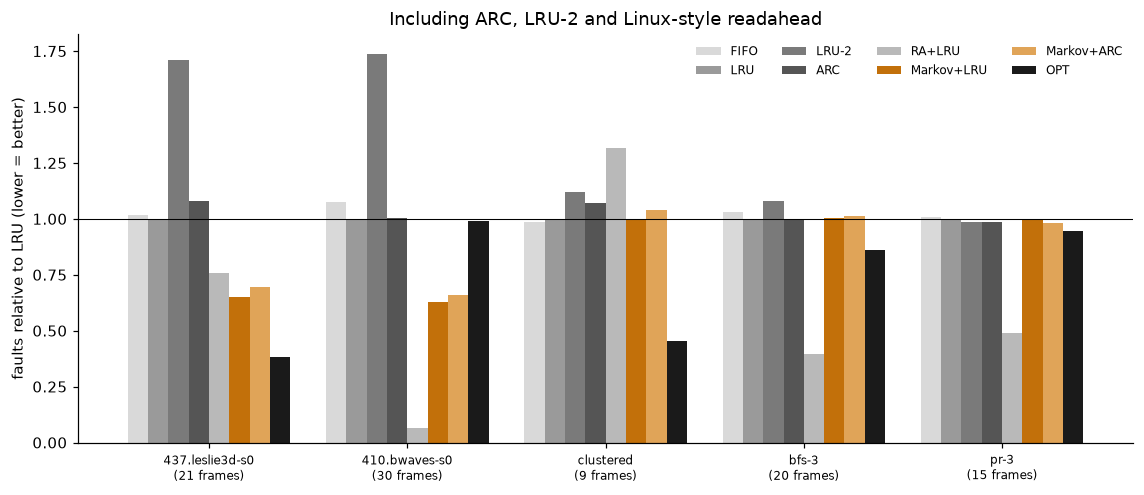

In [31]:
#cell 21 — ReadaheadPredictor + eviction-only sweep + head-to-head (saves after each configuration)
assert 'TRACE_DIR' in globals(), 'Run cell 0a (setup) first'

class ReadaheadPredictor:
    """
    Sequential readahead, modelled on the Linux page cache:
      - two consecutive pages (n, n+1) start a stream: fetch an initial window ahead
      - while the stream continues, each time the program reaches the window's async marker
        (half way through) fetch the next window, DOUBLE the window, up to max_window
      - any non-sequential access resets the stream
    Repeats of the same page are ignored (LLC traces contain many).
    Unlike the Markov predictor it returns a whole window of pages, and run_prefetch_sim
    prefetches every candidate returned, so pair it with AlwaysPrefetch.
    """

    def __init__(self, init_window=4, max_window=32, min_run=2, conf_k=None):
        self.conf_k = conf_k             # None: confidence 1.0 (original); k: run/(run+k), so a decider can gate short streams
        self.min_run = min_run           # consecutive pages needed to start a stream (2 = original)
        self.run = 0
        self.init_window = init_window
        self.max_window = max_window
        self.last = None
        self.win = 0
        self.issued = None               # highest page already requested
        self.pending = []
        self.n_issued = 0
        self.n_resets = 0

    def _issue(self, base, n):
        self.pending = [base + k for k in range(1, n + 1)]
        self.issued = base + n
        self.n_issued += n

    def update(self, history, actual_next):
        page = int(actual_next)
        self.pending = []
        if self.last is None:
            self.last, self.issued = page, page
            return
        if page == self.last:            # same page again: no information
            return
        if page == self.last + 1:        # sequential continuation
            self.last = page
            self.run += 1
            if self.win == 0:
                if self.run < self.min_run - 1:
                    return
                self.win = min(self.init_window, self.max_window)
                self._issue(page, self.win)
            elif page >= self.issued - self.win // 2:
                self.win = min(self.win * 2, self.max_window)
                self._issue(self.issued, self.win)
        else:                            # stream broken
            self.last, self.win, self.issued = page, 0, page
            self.run = 0
            self.n_resets += 1

    def predict(self, history, top_n=1):
        c = 1.0 if not self.conf_k else self.run / (self.run + self.conf_k)
        return [(p, c) for p in self.pending]

    def stats(self):
        return {'issued': self.n_issued, 'resets': self.n_resets}


def make_readahead(n_frames, min_run=2, conf_k=None):
    """Linux caps readahead at 128 KB (32 pages), larger than our whole simulated RAM,
    so scale the window to a quarter of memory."""
    mx = max(2, n_frames // 4)
    return ReadaheadPredictor(init_window=min(4, mx), max_window=mx, min_run=min_run, conf_k=conf_k)


for name, nf in (('sequential', 64), ('strided', 64), ('random', 64)):
    if name in TRACES:
        b = run_policy(TRACES[name], nf, LRU)['faults']
        g = run_prefetch_sim(TRACES[name], nf, LRU, make_readahead(nf), AlwaysPrefetch())['faults']
        print(f'readahead on {name:10s} (synthetic): LRU={b:6d}  readahead={g:6d}')
        assert (g < 0.05 * b) if name == 'sequential' else (abs(g - b) <= 0.01 * b)

# (a) eviction policies alone
rows = []
for name, t in TRACES.items():
    if name in ('sequential', 'strided', 'cyclic'):      # degenerate: every policy identical
        continue
    ws, seen = len(np.unique(t.pages)), set()
    for ratio in (0.01, 0.02, 0.05, 0.10):
        nf = max(8, int(ws * ratio))
        if nf in seen:
            continue
        seen.add(nf)
        rows.append({'trace': name, 'ratio': ratio, 'frames': nf,
                     **{p: run_policy(t, nf, P)['faults'] for p, P in POLICIES_EXTENDED.items()}})
ev = pd.DataFrame(rows)
ev.to_csv(f'{RESULTS}/phase8_eviction_only.csv', index=False)
red = ev.set_index(['trace', 'ratio', 'frames'])
print('\n(a) eviction only, fault reduction vs LRU (positive = better than LRU):')
display(pd.DataFrame({p: ((red.LRU - red[p]) / red.LRU).round(4) for p in ('FIFO', 'Clock', 'LRU-2', 'ARC', 'OPT')}))

# head-to-head, resumable
CSV8 = 'phase8_head_to_head.csv'
rows = saved_rows(CSV8)
done = {(r['trace'], int(r['frames'])) for r in rows}
for tname, nf in H2H_CONFIGS:
    if tname not in TRACES or (tname, nf) in done:
        continue
    t = TRACES[tname]
    r = {'trace': tname, 'frames': nf, **{p: run_policy(t, nf, P)['faults'] for p, P in POLICIES_EXTENDED.items()}}
    r['RA+LRU'] = run_prefetch_sim(t, nf, LRU, make_readahead(nf), AlwaysPrefetch())['faults']
    r['RA+ARC'] = run_prefetch_sim(t, nf, ARC, make_readahead(nf), AlwaysPrefetch())['faults']
    r['Markov+LRU'] = run_prefetch_sim_ghost(t, nf, LRU, make_predictor('hybrid'), CostAwareGhost())['faults']
    r['Markov+ARC'] = run_prefetch_sim_ghost(t, nf, ARC, make_predictor('hybrid'), CostAwareGhost())['faults']
    rows.append(r)
    pd.DataFrame(rows).to_csv(f'{RESULTS}/{CSV8}', index=False)
    print(f'{tname:18s} frames={nf:3d} done', flush=True)
d = pd.DataFrame(rows).set_index(['trace', 'frames'])
print('\npage faults (lower = better):')
display(d[['FIFO', 'Clock', 'LRU', 'LRU-2', 'ARC', 'RA+LRU', 'RA+ARC', 'Markov+LRU', 'Markov+ARC', 'OPT']])
room = d.LRU - d.OPT
print('(a) share of the LRU->OPT gap closed by a smarter eviction policy:')
display(pd.DataFrame({'gap': (room / d.LRU).round(3), 'LRU-2 closes': ((d.LRU - d['LRU-2']) / room).round(3),
                      'ARC closes': ((d.LRU - d.ARC) / room).round(3)}))
print('(b) gain from prediction on ARC and on LRU; (c) Markov vs readahead (positive = Markov better):')
display(pd.DataFrame({'gain on ARC': ((d.ARC - d['Markov+ARC']) / d.ARC).round(4),
                      'gain on LRU': ((d.LRU - d['Markov+LRU']) / d.LRU).round(4),
                      'readahead vs LRU': ((d.LRU - d['RA+LRU']) / d.LRU).round(4),
                      'Markov vs readahead': ((d['RA+LRU'] - d['Markov+LRU']) / d['RA+LRU']).round(4)}))

cols = ['FIFO', 'LRU', 'LRU-2', 'ARC', 'RA+LRU', 'Markov+LRU', 'Markov+ARC', 'OPT']
colors = ['#d9d9d9', '#9a9a9a', '#7a7a7a', '#555555', '#b9b9b9', AMBER, '#e0a458', '#1a1a1a']
ax = d[cols].div(d.LRU, axis=0).plot(kind='bar', figsize=(10.5, 4.6), width=0.82, color=colors)
ax.axhline(1.0, color='black', lw=0.7); ax.set_ylabel('faults relative to LRU (lower = better)'); ax.set_xlabel('')
ax.set_xticklabels([f'{a}\n({b} frames)' for a, b in d.index], rotation=0, fontsize=8)
ax.set_title('Including ARC, LRU-2 and Linux-style readahead'); ax.legend(ncol=4, fontsize=8, frameon=False)
plt.tight_layout(); plt.savefig(f'{FIG}/fig_phase8_head_to_head.png', dpi=200); plt.show()

## Phases 9-10: readahead + delta-Markov
### Cell 22 — combining readahead with a delta-Markov predictor
Readahead beat Markov on 3 of the original 4 traces, so readahead became a **baseline to beat**. Readahead covers *new*
pages in a run (a page-number Markov model cannot predict a page it has never seen); a **delta-Markov** tier learns
repeating gap patterns anywhere in the address space. `StreamMarkovPredictor` returns the readahead window first, then the
Markov guess. Every design choice here was made on the 25% warm-up portion only. `Comb` variants use `always`.

In [32]:
#cell 22 — delta-Markov, TopN, StreamMarkovPredictor, and the improvement table
assert 'TRACE_DIR' in globals(), 'Run cell 0a (setup) first'

class DeltaMarkovPredictor:
    """
    Markov chain over page DELTAS (gaps), not page numbers (Phase 10 idea).
    Context = last `order` deltas, successor = next delta; prediction = last page + delta.
    One entry covers a pattern anywhere in the address space, so it can predict pages it has
    never seen. A zero delta (same page again) is never predicted. Same bounded-table
    machinery (and cost per entry) as MarkovPredictor.
    """

    def __init__(self, capacity=256, max_succ=2, order=2, decay_every=25_000):
        self.order = order
        self.mk = MarkovPredictor(capacity, max_succ, order, decay_every)

    def _deltas(self, history):
        h = history[-(self.order + 1):]
        return [h[i] - h[i - 1] for i in range(1, len(h))]

    def update(self, history, actual_next):
        if len(history) < self.order + 1:
            return
        d = actual_next - history[-1]
        if d != 0:
            self.mk.update(self._deltas(history), d)

    def predict(self, history, top_n=1):
        if len(history) < self.order + 1:
            return []
        return [(history[-1] + d, c) for d, c in self.mk.predict(self._deltas(history), top_n) if d != 0]

    def stats(self):
        return self.mk.stats()


class DeltaHybridPredictor(HybridPredictor):
    """order-2 page Markov -> order-1 page Markov -> delta Markov -> stride."""

    def __init__(self, capacity=256, max_succ=2, decay_every=25_000):
        super().__init__(capacity, max_succ, decay_every)
        self.dm = DeltaMarkovPredictor(capacity, max_succ, 2, decay_every)
        self.source_counts['delta'] = 0

    def predict(self, history, top_n=1):
        for tag, p in (('m2', self.m2), ('m1', self.m1), ('delta', self.dm), ('stride', self.st)):
            r = p.predict(history, top_n)
            if r:
                self.source_counts[tag] += 1
                return r
        self.source_counts['none'] += 1
        return []

    def update(self, history, actual_next):
        super().update(history, actual_next)
        self.dm.update(history, actual_next)


class TopN:
    """Wrap a predictor so it always returns its top-n guesses (n=2: prefetch the two likeliest)."""

    def __init__(self, inner, n=2):
        self.inner, self.n = inner, n

    def update(self, history, actual_next):
        self.inner.update(history, actual_next)

    def predict(self, history, top_n=1):
        return self.inner.predict(history, top_n=self.n)

    def stats(self):
        return self.inner.stats()


class StreamMarkovPredictor:
    """
    Readahead + Markov hybrid (Phase 9a, item 1 of the improvement plan).
    Readahead covers NEW pages in a sequential run (Markov cannot predict a page it has
    never seen); the Markov hybrid covers repeating patterns. Both learn on every access.
    predict() returns the readahead window first (confidence 1.0), then the Markov guess if
    it is not already in the list. No new tunable parameters: the readahead window comes
    from make_readahead(n_frames) and the Markov side from the frozen config.
    """

    def __init__(self, n_frames, markov=None, readahead=None):
        self.ra = readahead or make_readahead(n_frames)
        self.mk = markov or make_predictor('hybrid')
        self.n_ra = self.n_mk = 0

    def update(self, history, actual_next):
        self.ra.update(history, actual_next)
        self.mk.update(history, actual_next)

    def predict(self, history, top_n=1):
        out = list(self.ra.predict(history, top_n))
        have = {p for p, _ in out}
        self.n_ra += len(out)
        for p, c in self.mk.predict(history, top_n):
            if p not in have:
                out.append((p, c))
                self.n_mk += 1
        return out

    def stats(self):
        return {'ra_candidates': self.n_ra, 'markov_candidates': self.n_mk,
                **{'ra_' + k: v for k, v in self.ra.stats().items()}}


rows = []
for tname, f in (('clustered', 9), ('437.leslie3d-s0', 21), ('410.bwaves-s0', 30), ('bfs-3', 20), ('pr-3', 15)):
    if tname not in TRACES:
        print('skipping', tname); continue
    t = TRACES[tname]
    opt = run_policy(t, f, OPTFast)['faults']
    for P in (LRU, ARC):
        d2 = lambda: TopN(make_predictor('delta-hybrid'), 2)
        rows.append(dict(
            trace=tname, frames=f, policy=P.__name__, base=run_policy(t, f, P)['faults'],
            RA=run_prefetch_sim(t, f, P, make_readahead(f), AlwaysPrefetch())['faults'],
            Mk_gh=run_prefetch_sim_ghost(t, f, P, make_predictor('hybrid'), CostAwareGhost())['faults'],
            Mk_d_t2=run_prefetch_sim_ghost(t, f, P, d2(), CostAwareGhost())['faults'],
            Comb=run_prefetch_sim(t, f, P, StreamMarkovPredictor(f), AlwaysPrefetch())['faults'],
            Comb_d_t2=run_prefetch_sim(t, f, P, StreamMarkovPredictor(f, markov=d2()), AlwaysPrefetch())['faults'],
            OPT=opt))
    print(f'{tname:18s} done', flush=True)
imp = pd.DataFrame(rows)
imp['best_vs_base'] = 1 - imp[['RA', 'Mk_gh', 'Mk_d_t2', 'Comb', 'Comb_d_t2']].min(axis=1) / imp['base']
imp.to_csv(f'{RESULTS}/improvements.csv', index=False)
print('page faults (lower = better); clustered is synthetic:')
display(imp)

clustered          done
437.leslie3d-s0    done
410.bwaves-s0      done
bfs-3              done
pr-3               done
page faults (lower = better); clustered is synthetic:


,trace,frames,policy,base,RA,Mk_gh,Mk_d_t2,Comb,Comb_d_t2,OPT,best_vs_base
0,clustered,9,LRU,5803,7645,5798,5861,7095,6905,2637,0.000862
1,clustered,9,ARC,6207,8025,6029,6083,7352,7053,2637,0.028677
2,437.leslie3d-s0,21,LRU,15313,11624,9956,8853,8308,5287,5881,0.654738
3,437.leslie3d-s0,21,ARC,16553,14166,10667,9691,9247,6174,5881,0.627016
4,410.bwaves-s0,30,LRU,3140,204,1969,766,205,234,3112,0.935032
5,410.bwaves-s0,30,ARC,3147,266,2069,986,280,262,3112,0.916746
6,bfs-3,20,LRU,7394,2924,7427,6706,3122,3084,6349,0.604544
7,bfs-3,20,ARC,7368,2710,7474,6740,3346,3314,6349,0.632193
8,pr-3,15,LRU,5905,2905,5872,5768,2874,2675,5591,0.546994
9,pr-3,15,ARC,5825,2827,5796,5682,2794,2595,5591,0.554506


## Phases 14-16: the final system
### Cell 23 — shadow-directory feedback
The ghost list was biased upwards once readahead was added (on `clustered@9` it reported *winning* while prefetching was
losing). The fix: a **shadow directory**, a no-prefetch copy of the eviction policy that stores page IDs only (8 B per
tracked frame, ~0.2% of RAM), optionally hash-sampled (SHARDS, Waldspurger et al., FAST 2015). With `sample = 1` its
estimate *equals* the true per-epoch delta, which this cell checks.

In [33]:
#cell 23 — CostAwareDirectory, run_prefetch_sim_dir, and ghost vs directory on the synthetic stress case
assert 'TRACE_DIR' in globals(), 'Run cell 0a (setup) first'

class CostAwareDirectory(CostAwareFaultDelta):
    """
    Phase 14. Fault-delta feedback from a SHADOW DIRECTORY: a no-prefetch copy of the eviction
    policy that stores page IDs only (no page data; 8 B per tracked frame). Optionally sampled by
    page-number hash (SHARDS, Waldspurger et al., FAST 2015): track a fraction `sample` of pages in
    a directory of sample x n_frames entries and scale the measured delta by 1/sample.
    Per-epoch (like CostAwareGhost), unlike the running-total oracle. Use run_prefetch_sim_dir.
    """
    name = 'cost-aware-dir'

    def __init__(self, sample=1.0, **kw):
        super().__init__(**kw)
        self.sample = sample

    def directory_update(self, est_delta):
        self._adapt(est_delta / max(1, self.epoch))


def sampled(page, rate):
    """Deterministic hash sampling of page numbers (SHARDS-style). rate=1.0 keeps every page."""
    if rate >= 1.0:
        return True
    return ((int(page) * 2654435761) & 0xFFFFFFFF) < rate * 4294967296


def run_prefetch_sim_dir(trace, n_frames, policy_cls, predictor, decider, hist_len=8, log=None):
    """
    Phase 14: feedback from a shadow directory (page IDs only, no-prefetch copy of the policy).
    The directory covers the sampled pages only, with sample x n_frames entries; estimated
    delta per epoch = (directory faults - real faults on sampled pages) / sample.
    A full shadow engine still runs, but only to LOG the true delta; the decider never sees it.
    Returns stats plus 'epoch_log' = [(estimated_delta, true_delta), ...] and 'dir_entries'.
    """
    s = decider.sample
    d_frames = max(1, round(n_frames * s))
    eng = MemoryEngine(n_frames, policy_cls(pages=trace.pages))
    eng.log = log
    shadow = MemoryEngine(n_frames, policy_cls(pages=trace.pages))
    direc = MemoryEngine(d_frames, policy_cls(pages=trace.pages))
    history, prev_wasted, log = [], 0, []
    real_s = dir_s = prev_real = prev_shadow = 0

    for i, page, _ in trace.stream():
        was_pf = eng.prefetched.get(page, False)
        fault = eng.access(page, i)
        shadow.access(page, i)
        if sampled(page, s):
            real_s += fault
            dir_s += direc.access(page, i)
        if was_pf:
            decider.feedback(page, True)
        if eng.n_pf_wasted > prev_wasted:
            for _ in range(eng.n_pf_wasted - prev_wasted):
                decider.feedback(None, False)
            prev_wasted = eng.n_pf_wasted

        if eng.n_access % decider.epoch == 0:
            est = (dir_s - real_s) / s
            true = (shadow.n_fault - prev_shadow) - (eng.n_fault - prev_real)
            log.append((est, true))
            real_s = dir_s = 0
            prev_real, prev_shadow = eng.n_fault, shadow.n_fault
            decider.directory_update(est)

        history.append(page)
        if len(history) > hist_len:
            history.pop(0)
        if len(history) >= 2:
            predictor.update(history[:-1], page)

        for cand, conf in predictor.predict(history, top_n=1):
            if cand in eng.resident:
                continue
            state = {'free_frames': eng.n_frames - len(eng.resident),
                     'n_frames': eng.n_frames, 'n_prefetch': eng.n_prefetch,
                     'n_access': eng.n_access, 'n_fault': eng.n_fault}
            if decider.decide(cand, conf, state):
                eng.prefetch(cand, i)

    st = eng.stats()
    st['decider'] = decider.name
    st.update(decider.stats())
    st['epoch_log'] = log
    st['dir_entries'] = d_frames
    return st


rows = []
for tname, f in (('clustered', 6), ('clustered', 9)):
    if tname not in TRACES:
        continue
    t = TRACES[tname]
    lru = run_policy(t, f, LRU)['faults']
    gated = lambda: StreamMarkovPredictor(f, markov=make_predictor('delta-hybrid'), readahead=make_readahead(f, conf_k=1))
    g = run_prefetch_sim_ghost(t, f, LRU, gated(), CostAwareGhost())
    s = run_prefetch_sim_dir(t, f, LRU, gated(), CostAwareDirectory())
    assert all(e == tr for e, tr in s['epoch_log']), 'with sample=1 the directory must give the exact delta'
    rows.append({'trace': tname, 'frames': f, 'LRU': lru, 'ghost': g['faults'], 'directory': s['faults'],
                 'ghost_vs_LRU': round((lru - g['faults']) / lru, 4), 'directory_vs_LRU': round((lru - s['faults']) / lru, 4)})
print('readahead + delta-Markov (gated), LRU underneath (synthetic):')
display(pd.DataFrame(rows))
print('directory estimate == true delta in every epoch: PASS')

readahead + delta-Markov (gated), LRU underneath (synthetic):


,trace,frames,LRU,ghost,directory,ghost_vs_LRU,directory_vs_LRU
0,clustered,6,20344,20498,20569,-0.0076,-0.0111
1,clustered,9,5803,7053,5948,-0.2154,-0.0250


directory estimate == true delta in every epoch: PASS


### Cell 24 — the final system (frozen)
**Readahead + delta-Markov predictor → fault-delta decider fed by a shadow directory → LRU.** The controller
(`epoch=1000, step=0.1, dead_band=0.002`) and the budget (no cap) were chosen on the **warm-up portion only** (cell 28) and
then frozen. Do not retune it on the evaluation traces.

In [34]:
#cell 24 — the final system in one call
assert 'TRACE_DIR' in globals(), 'Run cell 0a (setup) first'

CONTROLLER_FROZEN = dict(epoch=1000, step=0.1, dead_band=0.002, budget_ratio=1.01)   # chosen in cell 28, warm-up only


def make_final_predictor(n_frames):
    return StreamMarkovPredictor(n_frames, markov=make_predictor('delta-hybrid'),
                                 readahead=make_readahead(n_frames, conf_k=1))


def make_final_decider(sample=1.0):
    return CostAwareDirectory(sample=sample, **CONTROLLER_FROZEN)


def run_final(trace, n_frames, policy_cls=LRU, log=None, sample=1.0):
    return run_prefetch_sim_dir(trace, n_frames, policy_cls, make_final_predictor(n_frames),
                                make_final_decider(sample), log=log)


for tname, f in (('437.leslie3d-s0', 21), ('clustered', 9)):
    if tname in TRACES:
        t = TRACES[tname]
        lru, s = run_policy(t, f, LRU)['faults'], run_final(t, f)
        print(f"{tname:16s}@{f}: LRU {lru:6d}   final {s['faults']:6d}   vs_LRU {(lru - s['faults']) / lru:+.4f}   "
              f"prefetches {s['prefetches']}   precision {s['pf_precision']:.3f}")

437.leslie3d-s0 @21: LRU  15313   final   8133   vs_LRU +0.4689   prefetches 16946   precision 0.455
clustered       @9: LRU   5803   final   5942   vs_LRU -0.0240   prefetches 1831   precision 0.759


## Phases 17-18: evaluation on 22 real traces
### Cell 25 — robustness (no retuning)
Every system on all 22 real traces at RAM = 1% and 5% of the working set (44 points), LRU underneath. Columns:
`RA` readahead · `Markov` original hybrid + ghost · `Comb_d` readahead + delta-Markov (always) · `Comb_d_t2` with top-2 ·
`Comb_d_gated` gated by the ghost list · `Comb_d_dir` gated by the shadow directory · `Final` the frozen final system.
**Long** (roughly 1-2 hours for all 22 traces); saves after every point and resumes.

In [35]:
#cell 25 — robustness on 22 real traces x {1%, 5%} (resumable)
assert 'TRACE_DIR' in globals(), 'Run cell 0a (setup) first'
assert 'run_final' in globals(), 'run cells 11-24 first'

CSV_R = 'robustness.csv'
rows = saved_rows(CSV_R)
have = {(r['trace'], r['ratio']) for r in rows}
for name in available(REAL_ALL):
    if all((name, ratio) in have for ratio in (0.01, 0.05)):
        continue
    t = load_trace(name, limit=TRACE_LIMIT)
    ws = len(np.unique(t.pages))
    for ratio in (0.01, 0.05):
        if (name, ratio) in have:
            continue
        f = max(8, int(ws * ratio))
        mk = lambda: make_predictor('delta-hybrid')
        r = dict(trace=name, ratio=ratio, frames=f, ws=ws, LRU=run_policy(t, f, LRU)['faults'],
                 ARC=run_policy(t, f, ARC)['faults'], OPT=run_policy(t, f, OPTFast)['faults'])
        r['RA'] = run_prefetch_sim(t, f, LRU, make_readahead(f), AlwaysPrefetch())['faults']
        r['Markov'] = run_prefetch_sim_ghost(t, f, LRU, make_predictor('hybrid'), CostAwareGhost())['faults']
        r['Comb_d'] = run_prefetch_sim(t, f, LRU, StreamMarkovPredictor(f, markov=mk()), AlwaysPrefetch())['faults']
        r['Comb_d_t2'] = run_prefetch_sim(t, f, LRU, StreamMarkovPredictor(f, markov=TopN(mk(), 2)), AlwaysPrefetch())['faults']
        r['Comb_d_gated'] = run_prefetch_sim_ghost(
            t, f, LRU, StreamMarkovPredictor(f, markov=mk(), readahead=make_readahead(f, conf_k=1)), CostAwareGhost())['faults']
        r['Comb_d_dir'] = run_prefetch_sim_dir(
            t, f, LRU, StreamMarkovPredictor(f, markov=mk(), readahead=make_readahead(f, conf_k=1)), CostAwareDirectory())['faults']
        r['Final'] = run_final(t, f)['faults']
        rows.append(r)
        pd.DataFrame(rows).to_csv(f'{RESULTS}/{CSV_R}', index=False)
        print(f"{name:18s} {ratio:.0%}  frames={f:5d}  LRU={r['LRU']:7d}  RA={r['RA']:7d}  Final={r['Final']:7d}", flush=True)

rb = pd.DataFrame(rows)
SYS = ['ARC', 'RA', 'Markov', 'Comb_d', 'Comb_d_t2', 'Comb_d_gated', 'Comb_d_dir', 'Final']
vs = rb[['trace', 'ratio', 'frames']].copy()
for c in SYS + ['OPT']:
    vs[c] = ((rb.LRU - rb[c]) / rb.LRU).round(3)
print('vs_LRU (positive = fewer faults than LRU):')
display(vs)
summ = pd.DataFrame({'mean': vs[SYS].mean(), 'median': vs[SYS].median(), 'worst': vs[SYS].min(),
                     'worse_than_LRU': (vs[SYS] < 0).sum()}).round(3)
print(f'over {len(rb)} points ({rb.trace.nunique()} traces x {rb.ratio.nunique()} RAM sizes):')
display(summ)
print(f"Final vs readahead: fewer faults in {(rb.Final < rb.RA).sum()}, equal {(rb.Final == rb.RA).sum()}, "
      f"more {(rb.Final > rb.RA).sum()};  below OPT in {(rb.Final < rb.OPT).sum()} of {len(rb)}")

410.bwaves-s0      1%  frames=   30  LRU=   3140  RA=    204  Final=    205
410.bwaves-s0      5%  frames=  152  LRU=   3135  RA=    197  Final=    197
410.bwaves-s1      1%  frames=   30  LRU=   3140  RA=    201  Final=    195
410.bwaves-s1      5%  frames=  152  LRU=   3136  RA=    189  Final=    189
410.bwaves-s2      1%  frames=    8  LRU=    631  RA=    753  Final=    652
410.bwaves-s2      5%  frames=   13  LRU=    499  RA=    507  Final=    456
437.leslie3d-s0    1%  frames=   21  LRU=  15313  RA=  11624  Final=   8133
437.leslie3d-s0    5%  frames=  106  LRU=   3290  RA=   1604  Final=   1512
437.leslie3d-s1    1%  frames=   22  LRU=  11771  RA=   9097  Final=   6873
437.leslie3d-s1    5%  frames=  112  LRU=   3269  RA=   1313  Final=   1262
437.leslie3d-s2    1%  frames=   22  LRU=  11760  RA=   9224  Final=   6715
437.leslie3d-s2    5%  frames=  112  LRU=   3267  RA=   1389  Final=   1363
433.milc-s0        1%  frames=  232  LRU=  23269  RA=   2700  Final=   2700
433.milc-s0 

,trace,ratio,frames,ARC,RA,Markov,Comb_d,Comb_d_t2,Comb_d_gated,Comb_d_dir,Final,OPT
0,410.bwaves-s0,0.01,30,-0.002,0.935,0.373,0.935,0.925,0.934,0.934,0.935,0.009
1,410.bwaves-s0,0.05,152,-0.001,0.937,0.374,0.937,0.937,0.937,0.937,0.937,0.027
2,410.bwaves-s1,0.01,30,-0.002,0.936,0.353,0.938,0.897,0.937,0.937,0.938,0.009
3,410.bwaves-s1,0.05,152,-0.002,0.940,0.353,0.940,0.940,0.939,0.939,0.940,0.027
4,410.bwaves-s2,0.01,8,-0.052,-0.193,0.024,-0.063,-0.154,-0.032,-0.014,-0.033,0.288
5,410.bwaves-s2,0.05,13,-0.020,-0.016,0.092,0.086,0.038,0.084,0.084,0.086,0.291
6,437.leslie3d-s0,0.01,21,-0.081,0.241,0.350,0.469,0.655,0.469,0.469,0.469,0.616
7,437.leslie3d-s0,0.05,106,-0.002,0.512,0.047,0.541,0.542,0.540,0.540,0.540,0.092
8,437.leslie3d-s1,0.01,22,-0.037,0.227,0.244,0.416,0.588,0.416,0.416,0.416,0.597
9,437.leslie3d-s1,0.05,112,-0.004,0.598,0.042,0.614,0.614,0.611,0.611,0.614,0.056


over 44 points (22 traces x 2 RAM sizes):


,mean,median,worst,worse_than_LRU
ARC,-0.005,-0.000,-0.082,22
RA,0.507,0.550,-0.193,2
Markov,0.077,0.015,-0.003,1
Comb_d,0.550,0.593,-0.063,1
Comb_d_t2,0.566,0.618,-0.154,1
Comb_d_gated,0.516,0.568,-0.032,1
Comb_d_dir,0.526,0.568,-0.014,1
Final,0.550,0.593,-0.033,1


Final vs readahead: fewer faults in 34, equal 8, more 2;  below OPT in 30 of 44


### Cell 26 — break-even prefetch cost
Fault counts hide the I/O that prefetching adds. `c* = (LRU faults − faults) / prefetches` is how expensive one prefetch may
be, as a fraction of one fault's stall, before the system loses to plain LRU. `c* ≥ 1` would mean it wins even if a prefetch
stalls like a fault. Saves after each trace.

In [36]:
#cell 26 — break-even cost at RAM = 1% (resumable)
assert 'TRACE_DIR' in globals(), 'Run cell 0a (setup) first'

CSV_B = 'breakeven.csv'
rows = saved_rows(CSV_B)
done = {r['trace'] for r in rows}
for name in available(REAL_ALL):
    if name in done:
        continue
    t = load_trace(name, limit=TRACE_LIMIT)
    f = frames_for(t, 0.01)
    lru = run_policy(t, f, LRU)['faults']
    mk = lambda: make_predictor('delta-hybrid')
    systems = {
        'RA':        lambda: run_prefetch_sim(t, f, LRU, make_readahead(f), AlwaysPrefetch()),
        'Markov':    lambda: run_prefetch_sim_ghost(t, f, LRU, make_predictor('hybrid'), CostAwareGhost()),
        'Comb_d':    lambda: run_prefetch_sim(t, f, LRU, StreamMarkovPredictor(f, markov=mk()), AlwaysPrefetch()),
        'Comb_d_t2': lambda: run_prefetch_sim(t, f, LRU, StreamMarkovPredictor(f, markov=TopN(mk(), 2)), AlwaysPrefetch()),
        'Final':     lambda: run_final(t, f),
    }
    for s, run in systems.items():
        r = run()
        saved, pf = lru - r['faults'], r['prefetches']
        rows.append(dict(trace=name, frames=f, system=s, LRU=lru, faults=r['faults'], prefetches=pf,
                         precision=round(r['pf_precision'], 2), breakeven_c=round(saved / pf, 2) if pf else float('nan')))
    pd.DataFrame(rows).to_csv(f'{RESULTS}/{CSV_B}', index=False)
    print(name, 'done', flush=True)
be = pd.DataFrame(rows)
display(be.pivot(index='trace', columns='system', values='breakeven_c'))

410.bwaves-s0 done
410.bwaves-s1 done
410.bwaves-s2 done
437.leslie3d-s0 done
437.leslie3d-s1 done
437.leslie3d-s2 done
433.milc-s0 done
462.libquantum-s0 done
429.mcf-s0 done
bfs-3 done
bfs-10 done
pr-3 done
pr-10 done
450.soplex-s0 done
471.omnetpp-s0 done
473.astar-s0 done
459.GemsFDTD-s0 done
470.lbm-s0 done
482.sphinx3-s0 done
bc-3 done
cc-5 done
sssp-3 done


system,Comb_d,Comb_d_t2,Final,Markov,RA
trace,,,,,
410.bwaves-s0,0.76,0.59,0.76,0.88,0.86
410.bwaves-s1,0.75,0.44,0.75,0.87,0.86
410.bwaves-s2,-0.06,-0.07,-0.04,0.04,-0.66
429.mcf-s0,0.47,0.35,0.47,0.03,0.37
433.milc-s0,0.94,0.93,0.94,0.99,0.97
437.leslie3d-s0,0.42,0.44,0.42,0.92,0.30
437.leslie3d-s1,0.37,0.31,0.37,0.89,0.27
437.leslie3d-s2,0.36,0.29,0.36,0.91,0.25
450.soplex-s0,0.18,0.15,0.18,0.28,0.18


### Cell 27 — time model: does fewer faults mean faster?
Replays each run's events on an I/O timeline: compute time per access (unknown for LLC traces, so swept 0.1 / 1 / 10 µs),
prediction cost 0.2 µs per access, a 4 KB read takes 80 µs on an NVMe SSD with 8 channels or 5 ms on a one-channel HDD;
demand faults can queue behind prefetches; a prefetched page used before its read finishes stalls for the rest.
**These are model estimates with stated latencies, not measurements.** `speedup > 1` = faster than LRU. Saves after each trace.

In [37]:
#cell 27 — I/O timeline replay and estimated speed-up vs LRU (resumable)
assert 'TRACE_DIR' in globals(), 'Run cell 0a (setup) first'

DEVICES = {'NVMe SSD': dict(t_io=80e-6, channels=8), 'HDD': dict(t_io=5e-3, channels=1)}   # stated, not tuned
T_PRED = 0.2e-6                         # one table lookup + counter update per access
T_CPU_SWEEP = (0.1e-6, 1e-6, 10e-6)     # compute between two traced accesses: unknown, so swept


def replay(log, n_access, t_io, channels, t_cpu, t_pred=0.0):
    """Return a dict with total time and its parts (seconds)."""
    free = [0.0] * channels                 # channel free times (min-heap)
    heapq.heapify(free)
    ready = {}                              # page -> time its prefetch read completes
    t = 0.0
    stall_fault = stall_late = 0.0
    k, n = 0, len(log)
    for i in range(n_access):
        t += t_cpu + t_pred
        while k < n and log[k][1] == i:
            kind, _, page = log[k]
            k += 1
            if kind == 'U':                 # recorded at access time, before any fault of the same access
                r = ready.pop(page, 0.0)
                if r > t:
                    stall_late += r - t
                    t = r
            elif kind == 'F':
                start = max(t, heapq.heappop(free))
                done = start + t_io
                heapq.heappush(free, done)
                stall_fault += done - t
                t = done
            else:                           # 'P': issued after this access was served
                start = max(t, heapq.heappop(free))
                done = start + t_io
                heapq.heappush(free, done)
                ready[page] = done
    return {'time': t, 'stall_fault': stall_fault, 'stall_late': stall_late,
            'compute': n_access * t_cpu, 'predict': n_access * t_pred}


SYSTEMS = {   # name -> (runner, asks a predictor on every access?)
    'LRU':        (lambda t, f, log: run_prefetch_sim(t, f, LRU, make_predictor('hybrid'), NoPrefetch(), log=log), False),
    'Readahead':  (lambda t, f, log: run_prefetch_sim(t, f, LRU, make_readahead(f), AlwaysPrefetch(), log=log), True),
    'Markov':     (lambda t, f, log: run_prefetch_sim_ghost(t, f, LRU, make_predictor('hybrid'), CostAwareGhost(), log=log), True),
    'RA+dMarkov': (lambda t, f, log: run_prefetch_sim_dir(t, f, LRU, StreamMarkovPredictor(
        f, markov=make_predictor('delta-hybrid'), readahead=make_readahead(f, conf_k=1)), CostAwareDirectory(), log=log), True),
    'Final':      (lambda t, f, log: run_final(t, f, log=log), True),
}
CSV_T = 'time_model.csv'
rows = saved_rows(CSV_T)
done = {r['trace'] for r in rows}
for name in available(REAL_ALL):
    if name in done:
        continue
    t = load_trace(name, limit=TRACE_LIMIT)
    f = frames_for(t, 0.01)
    logs = {}
    for s, (run, _) in SYSTEMS.items():
        logs[s] = []
        logs[s + '_n'] = run(t, f, logs[s])['accesses']
    for dev, dv in DEVICES.items():
        for tc in T_CPU_SWEEP:
            base_t = replay(logs['LRU'], logs['LRU_n'], dv['t_io'], dv['channels'], tc)['time']
            for tp in (0.0, T_PRED):                      # without and with the CPU cost of predicting
                for s, (_, pred) in SYSTEMS.items():
                    tm = replay(logs[s], logs[s + '_n'], dv['t_io'], dv['channels'], tc, tp if pred else 0.0)
                    rows.append(dict(trace=name, frames=f, device=dev, t_cpu_us=tc * 1e6, t_pred_us=tp * 1e6, system=s,
                                     time_s=tm['time'], speedup=base_t / tm['time'], late_share=tm['stall_late'] / tm['time'],
                                     faults=sum(e[0] == 'F' for e in logs[s]), prefetches=sum(e[0] == 'P' for e in logs[s])))
    pd.DataFrame(rows).to_csv(f'{RESULTS}/{CSV_T}', index=False)
    print(name, 'done', flush=True)

tm = pd.DataFrame(rows)
tm = tm[tm.system != 'LRU']
for dev in DEVICES:
    sub = tm[(tm.device == dev) & (tm.t_cpu_us == 1.0) & (tm.t_pred_us > 0)]
    print(f'{dev}, 1 us compute per access, 0.2 us prediction: speed-up vs LRU (> 1 = faster)')
    display(sub.pivot(index='trace', columns='system', values='speedup').round(2))
g = tm[tm.t_pred_us > 0].groupby(['device', 't_cpu_us', 'system']).speedup
print('geometric mean over traces / number of traces slower than LRU:')
display(pd.DataFrame({'geomean': g.apply(lambda x: float(np.exp(np.log(x).mean()))),
                      'slower_than_LRU': g.apply(lambda x: int((x < 1).sum()))}).round(3).unstack('system'))

410.bwaves-s0 done
410.bwaves-s1 done
410.bwaves-s2 done
437.leslie3d-s0 done
437.leslie3d-s1 done
437.leslie3d-s2 done
433.milc-s0 done
462.libquantum-s0 done
429.mcf-s0 done
bfs-3 done
bfs-10 done
pr-3 done
pr-10 done
450.soplex-s0 done
471.omnetpp-s0 done
473.astar-s0 done
459.GemsFDTD-s0 done
470.lbm-s0 done
482.sphinx3-s0 done
bc-3 done
cc-5 done
sssp-3 done
NVMe SSD, 1 us compute per access, 0.2 us prediction: speed-up vs LRU (> 1 = faster)


system,Final,Markov,RA+dMarkov,Readahead
trace,,,,
410.bwaves-s0,1.71,0.95,1.71,1.71
410.bwaves-s1,1.71,0.95,1.71,1.71
410.bwaves-s2,0.81,0.86,0.83,0.83
429.mcf-s0,1.05,1.00,1.04,1.01
433.milc-s0,2.68,0.98,2.68,2.68
437.leslie3d-s0,1.24,1.07,1.24,1.14
437.leslie3d-s1,1.19,1.07,1.19,1.12
437.leslie3d-s2,1.16,1.04,1.16,1.11
450.soplex-s0,1.06,0.98,1.06,1.07


HDD, 1 us compute per access, 0.2 us prediction: speed-up vs LRU (> 1 = faster)


system,Final,Markov,RA+dMarkov,Readahead
trace,,,,
410.bwaves-s0,0.78,0.96,0.78,0.88
410.bwaves-s1,0.77,0.95,0.77,0.88
410.bwaves-s2,0.54,0.61,0.57,0.67
429.mcf-s0,0.89,0.95,0.90,0.97
433.milc-s0,0.95,1.00,0.95,0.97
437.leslie3d-s0,0.61,0.97,0.61,0.64
437.leslie3d-s1,0.58,0.97,0.58,0.62
437.leslie3d-s2,0.57,0.97,0.57,0.60
450.soplex-s0,0.50,0.85,0.50,0.67


geometric mean over traces / number of traces slower than LRU:


geomean                             slower_than_LRU                            
system              Final Markov RA+dMarkov Readahead           Final Markov RA+dMarkov Readahead
device   t_cpu_us                                                                                
HDD      0.1        0.698  0.928      0.708     0.801              22     22         22        22
         1.0        0.701  0.929      0.710     0.804              22     22         22        22
         10.0       0.725  0.938      0.735     0.831              21     20         21        21
NVMe SSD 0.1        1.585  0.956      1.477     1.601               3     19          3         2
         1.0        1.433  0.971      1.337     1.440               3     18          3         2
         10.0       1.192  0.996      1.124     1.188               3     17          3         2

### Cell 28 — *(optional)* how the frozen controller and budget were chosen
Re-derives `CONTROLLER_FROZEN` on the **first 25% of each trace only**. Rule fixed before the run: drop settings whose worst
case is more than 0.002 below the default's; take the highest mean; keep the default unless beaten by more than 0.002.
Slow (hundreds of runs), so it is off by default; with `RUN_TUNING = False` it only shows saved results.

In [38]:
#cell 28 — (optional) controller and budget tuning on the warm-up portion
assert 'TRACE_DIR' in globals(), 'Run cell 0a (setup) first'

RUN_TUNING = False
TUNE_NAMES = ['clustered'] + REAL_ALL[:13]               # the 13 traces available when the controller was tuned
TOL = 0.002

if RUN_TUNING:
    rows = saved_rows('tuning_controller.csv')
    have = {(r['trace'], r['epoch'], r['step'], r['dead_band']) for r in rows}
    for name in available(TUNE_NAMES):
        full = load_trace(name, limit=TRACE_LIMIT)
        w = Trace(name, full.pages[:full.split])           # warm-up portion only
        f = frames_for(full, 0.01)
        lru = run_policy(w, f, LRU)['faults']
        for ep, st, db in itertools.product((500, 1000, 2000, 4000), (0.05, 0.1, 0.2), (0.001, 0.002, 0.005)):
            if (name, ep, st, db) in have:
                continue
            p = StreamMarkovPredictor(f, markov=make_predictor('delta-hybrid'), readahead=make_readahead(f, conf_k=1))
            r = run_prefetch_sim_dir(w, f, LRU, p, CostAwareDirectory(epoch=ep, step=st, dead_band=db))
            rows.append(dict(trace=name, frames=f, epoch=ep, step=st, dead_band=db, LRU=lru, faults=r['faults'],
                             vs_LRU=(lru - r['faults']) / lru))
        pd.DataFrame(rows).to_csv(f'{RESULTS}/tuning_controller.csv', index=False)
        print(name, 'done', flush=True)
    rows = []
    for name in available(['clustered'] + REAL_ALL):
        full = load_trace(name, limit=TRACE_LIMIT)
        w = Trace(name, full.pages[:full.split]); f = frames_for(full, 0.01)
        lru = run_policy(w, f, LRU)['faults']
        for b in (0.35, 0.5, 0.75, 1.01):
            ctl = {**CONTROLLER_FROZEN, 'budget_ratio': b}
            r = run_prefetch_sim_dir(w, f, LRU, make_final_predictor(f), CostAwareDirectory(**ctl))
            rows.append(dict(trace=name, frames=f, budget=b, LRU=lru, faults=r['faults'], prefetches=r['prefetches'],
                             vs_LRU=(lru - r['faults']) / lru))
    pd.DataFrame(rows).to_csv(f'{RESULTS}/tuning_budget.csv', index=False)

for fname, keys, default in (('tuning_controller.csv', ['epoch', 'step', 'dead_band'], (2000, 0.05, 0.002)),
                             ('tuning_budget.csv', ['budget'], (0.35,))):
    rows = saved_rows(fname)
    if not rows:
        print(fname, 'not produced yet (set RUN_TUNING = True)'); continue
    s = pd.DataFrame(rows).groupby(keys).vs_LRU.agg(mean='mean', worst='min')
    dflt = s.loc[default if len(default) > 1 else default[0]]
    ok = s[s.worst >= dflt.worst - TOL]
    best = ok['mean'].idxmax()
    chosen = best if ok.loc[best, 'mean'] > dflt['mean'] + TOL else default
    print(f'{fname} (warm-up portion only): best 8 settings by mean vs_LRU')
    display(s.sort_values('mean', ascending=False).head(8).round(4))
    print('default:', default, ' chosen:', chosen)

tuning_controller.csv not produced yet (set RUN_TUNING = True)
tuning_budget.csv not produced yet (set RUN_TUNING = True)


### Cell 29 — component comparison: one component changed at a time
**Predictors** (stride, markov-o1, markov-o2, hybrid, delta-hybrid, readahead, and the final combination), all through the
same final decision layer; **deciders** (9 + the final one), all fed the same predictions (once from the original Markov
hybrid, once from the final predictor). Every real trace at 1% plus synthetic `clustered` as the danger test; LRU underneath.
Summaries average over the **real traces only** and report `clustered` in its own column. Long; resumable per trace.

In [39]:
#cell 29 — every predictor and every decider, side by side (resumable)
assert 'TRACE_DIR' in globals(), 'Run cell 0a (setup) first'

PREDICTORS = {
    'stride': lambda f: make_predictor('stride'), 'markov-o1': lambda f: make_predictor('markov-o1'),
    'markov-o2': lambda f: make_predictor('markov-o2'), 'hybrid': lambda f: make_predictor('hybrid'),
    'delta-hybrid': lambda f: make_predictor('delta-hybrid'), 'readahead': lambda f: make_readahead(f, conf_k=1),
    'final (readahead + delta-hybrid)': lambda f: make_final_predictor(f),
}
DECIDERS_ALL = {   # name -> (simulator, decider factory)
    'no-prefetch': (run_prefetch_sim, NoPrefetch), 'always': (run_prefetch_sim, AlwaysPrefetch),
    'fixed-0.3': (run_prefetch_sim, lambda: FixedThreshold(0.3)), 'fixed-0.6': (run_prefetch_sim, lambda: FixedThreshold(0.6)),
    'fixed-0.85': (run_prefetch_sim, lambda: FixedThreshold(0.85)), 'precision (cost-aware)': (run_prefetch_sim, CostAware),
    'fault-delta oracle': (run_prefetch_sim, CostAwareFaultDelta), 'ghost list': (run_prefetch_sim_ghost, CostAwareGhost),
    'shadow directory': (run_prefetch_sim_dir, CostAwareDirectory),
    'directory + frozen controller (final)': (run_prefetch_sim_dir, make_final_decider),
}
DECIDER_PREDICTORS = {'Markov hybrid (original)': lambda f: make_predictor('hybrid'),
                      'final predictor': lambda f: make_final_predictor(f)}


def timed(sim, t, f, pred, dec):
    log = []
    r = sim(t, f, LRU, pred, dec, log=log)
    return r, {dev: replay(log, r['accesses'], dv['t_io'], dv['channels'], 1e-6, T_PRED)['time'] for dev, dv in DEVICES.items()}


rp, rd = saved_rows('component_predictors.csv'), saved_rows('component_deciders.csv')
done = {r['trace'] for r in rp} & {r['trace'] for r in rd}
for name in available(['clustered'] + REAL_ALL):
    if name in done:
        continue
    t = load_trace(name, limit=TRACE_LIMIT)
    f = frames_for(t, 0.01)
    b, bsp = timed(run_prefetch_sim, t, f, make_predictor('hybrid'), NoPrefetch())
    lru = b['faults']
    rp = [r for r in rp if r['trace'] != name]; rd = [r for r in rd if r['trace'] != name]
    for pn, mk in PREDICTORS.items():
        q = eval_predictor(t, mk(f))
        r, sp = timed(run_prefetch_sim_dir, t, f, mk(f), make_final_decider())
        rp.append(dict(trace=name, frames=f, predictor=pn, coverage=q['coverage'], accuracy=q['accuracy'], useful=q['useful'],
                       LRU=lru, faults=r['faults'], vs_LRU=(lru - r['faults']) / lru, prefetches=r['prefetches'],
                       precision=r['pf_precision'], **{f'speedup_{d}': bsp[d] / sp[d] for d in DEVICES}))
    for pl, mkp in DECIDER_PREDICTORS.items():
        for dn, (sim, mkd) in DECIDERS_ALL.items():
            r, sp = timed(sim, t, f, mkp(f), mkd())
            rd.append(dict(trace=name, frames=f, predictions=pl, decider=dn, LRU=lru, faults=r['faults'],
                           vs_LRU=(lru - r['faults']) / lru, prefetches=r['prefetches'], precision=r['pf_precision'],
                           **{f'speedup_{d}': bsp[d] / sp[d] for d in DEVICES}))
    pd.DataFrame(rp).to_csv(f'{RESULTS}/component_predictors.csv', index=False)
    pd.DataFrame(rd).to_csv(f'{RESULTS}/component_deciders.csv', index=False)
    print(name, 'done', flush=True)


def summarise(df, key):
    real = df[df.trace != 'clustered']
    g = real.groupby(key, sort=False)
    return pd.DataFrame({
        'mean_vs_LRU': g.vs_LRU.mean(), 'median_vs_LRU': g.vs_LRU.median(), 'worst_vs_LRU': g.vs_LRU.min(),
        'worse_than_LRU': g.vs_LRU.apply(lambda x: int((x < -0.0005).sum())),
        'prefetch_per_access': g.prefetches.mean() / TRACE_LIMIT, 'precision': g.precision.mean(),
        'NVMe_speedup': g['speedup_NVMe SSD'].apply(lambda x: float(np.exp(np.log(x).mean()))),
        'HDD_speedup': g['speedup_HDD'].apply(lambda x: float(np.exp(np.log(x).mean()))),
        'clustered_vs_LRU': df[df.trace == 'clustered'].set_index(key).vs_LRU if 'clustered' in set(df.trace) else np.nan})


P, D = pd.DataFrame(rp), pd.DataFrame(rd)
sp = P[P.trace != 'clustered'].groupby('predictor', sort=False)[['coverage', 'accuracy', 'useful']].mean().join(summarise(P, 'predictor'))
sp.to_csv(f'{RESULTS}/component_predictors_summary.csv')
print(f'PREDICTORS, same final decider ({P.trace.nunique() - ("clustered" in set(P.trace))} real traces at 1%):')
display(sp.round(3))
sd = pd.concat({pl: summarise(D[D.predictions == pl], 'decider') for pl in DECIDER_PREDICTORS}, names=['predictions'])
sd.to_csv(f'{RESULTS}/component_deciders_summary.csv')
for pl in DECIDER_PREDICTORS:
    print(f'\nDECIDERS fed by: {pl}')
    display(sd.loc[pl].round(3))

clustered done
410.bwaves-s0 done
410.bwaves-s1 done
410.bwaves-s2 done
437.leslie3d-s0 done
437.leslie3d-s1 done
437.leslie3d-s2 done
433.milc-s0 done
462.libquantum-s0 done
429.mcf-s0 done
bfs-3 done
bfs-10 done
pr-3 done
pr-10 done
450.soplex-s0 done
471.omnetpp-s0 done
473.astar-s0 done
459.GemsFDTD-s0 done
470.lbm-s0 done
482.sphinx3-s0 done
bc-3 done
cc-5 done
sssp-3 done
PREDICTORS, same final decider (22 real traces at 1%):


,coverage,accuracy,useful,mean_vs_LRU,median_vs_LRU,worst_vs_LRU,worse_than_LRU,prefetch_per_access,precision,NVMe_speedup,HDD_speedup,clustered_vs_LRU
predictor,,,,,,,,,,,,
stride,0.044,0.231,0.027,0.058,0.007,0.000,0,0.008,0.689,1.009,0.996,-0.012
markov-o1,0.841,0.532,0.501,0.049,0.000,-0.008,3,0.017,0.227,1.009,0.936,-0.055
markov-o2,0.677,0.668,0.533,0.024,0.000,-0.011,3,0.003,0.236,1.002,0.974,0.002
hybrid,0.848,0.608,0.573,0.094,0.014,-0.003,1,0.027,0.425,1.011,0.916,-0.007
delta-hybrid,0.902,0.617,0.589,0.209,0.103,0.000,0,0.073,0.499,1.024,0.856,0.009
readahead,0.095,0.153,0.026,0.465,0.427,-0.025,1,0.092,0.603,1.508,0.828,-0.013
final (readahead + delta-hybrid),0.911,0.588,0.562,0.512,0.507,-0.033,1,0.136,0.551,1.493,0.701,-0.024



DECIDERS fed by: Markov hybrid (original)


,mean_vs_LRU,median_vs_LRU,worst_vs_LRU,worse_than_LRU,prefetch_per_access,precision,NVMe_speedup,HDD_speedup,clustered_vs_LRU
decider,,,,,,,,,
no-prefetch,0.000,0.000,0.000,0,0.000,0.000,1.000,1.000,0.000
always,0.093,0.014,-0.014,3,0.032,0.419,1.008,0.902,0.001
fixed-0.3,0.093,0.014,-0.014,3,0.032,0.419,1.008,0.902,0.001
fixed-0.6,0.093,0.015,-0.001,1,0.022,0.478,1.013,0.946,-0.009
fixed-0.85,0.083,0.016,0.000,0,0.020,0.515,1.011,0.967,-0.002
precision (cost-aware),0.093,0.015,-0.001,1,0.021,0.476,1.014,0.949,-0.012
fault-delta oracle,0.094,0.014,-0.002,3,0.028,0.422,1.010,0.911,-0.005
ghost list,0.092,0.014,-0.003,1,0.022,0.434,1.011,0.930,0.001
shadow directory,0.094,0.014,-0.003,2,0.029,0.422,1.010,0.910,-0.012



DECIDERS fed by: final predictor


,mean_vs_LRU,median_vs_LRU,worst_vs_LRU,worse_than_LRU,prefetch_per_access,precision,NVMe_speedup,HDD_speedup,clustered_vs_LRU
decider,,,,,,,,,
no-prefetch,0.000,0.000,0.000,0,0.000,0.000,1.000,1.000,0.000
always,0.512,0.507,-0.063,1,0.137,0.549,1.491,0.696,-0.215
fixed-0.3,0.512,0.507,-0.063,1,0.137,0.549,1.491,0.696,-0.215
fixed-0.6,0.288,0.116,0.000,0,0.069,0.605,1.211,0.888,-0.055
fixed-0.85,0.198,0.064,0.000,0,0.046,0.644,1.070,0.953,-0.002
precision (cost-aware),0.268,0.112,0.000,0,0.050,0.595,1.158,0.892,-0.052
fault-delta oracle,0.491,0.507,0.000,0,0.111,0.553,1.394,0.713,-0.017
ghost list,0.479,0.507,-0.032,1,0.087,0.552,1.386,0.731,-0.215
shadow directory,0.490,0.507,-0.014,1,0.111,0.553,1.392,0.711,-0.025


### Cell 30 — results at a glance
Built from the saved files only (no new simulation): the final system against readahead, the original Markov system and
OPT on every real trace, and the estimated time. What to look for: the final system has the most fault reduction, but in
estimated time it roughly ties readahead; on a one-channel HDD every prefetcher is slower than LRU.

fault reduction vs LRU: mean and worst over traces, per RAM size


RA        Markov         Final       
        mean    min   mean    min   mean    min
ratio                                          
0.01   0.458 -0.193  0.092 -0.003  0.512 -0.033
0.05   0.556 -0.016  0.062  0.000  0.588  0.000

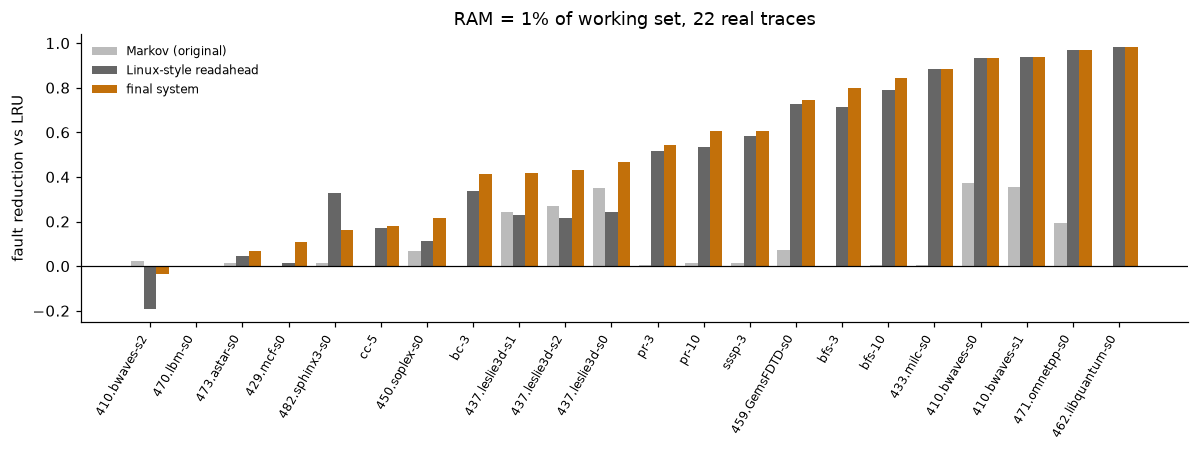

estimated speed-up vs LRU (geometric mean over traces; model, not measurement):


system             Final  Markov  RA+dMarkov  Readahead
device   t_cpu_us                                      
HDD      0.1        0.70    0.93        0.71       0.80
         1.0        0.70    0.93        0.71       0.80
         10.0       0.73    0.94        0.73       0.83
NVMe SSD 0.1        1.59    0.96        1.48       1.60
         1.0        1.43    0.97        1.34       1.44
         10.0       1.19    1.00        1.12       1.19

In [40]:
#cell 30 — headline table and figures from robustness.csv and time_model.csv
assert 'TRACE_DIR' in globals(), 'Run cell 0a (setup) first'

rb = pd.DataFrame(saved_rows('robustness.csv'))
if len(rb):
    v = rb[['trace', 'ratio', 'frames']].copy()
    for c in ('RA', 'Markov', 'Final', 'OPT'):
        v[c] = (rb.LRU - rb[c]) / rb.LRU
    head = v.groupby('ratio')[['RA', 'Markov', 'Final']].agg(['mean', 'min']).round(3)
    print('fault reduction vs LRU: mean and worst over traces, per RAM size')
    display(head)
    one = v[v.ratio == 0.01].set_index('trace').sort_values('Final')
    fig, ax = plt.subplots(figsize=(11, 4.2))
    x = np.arange(len(one)); w = 0.27
    ax.bar(x - w, one.Markov, w, color='#bbbbbb', label='Markov (original)')
    ax.bar(x, one.RA, w, color='#666666', label='Linux-style readahead')
    ax.bar(x + w, one.Final, w, color=AMBER, label='final system')
    ax.axhline(0, color='black', lw=0.8); ax.set_xticks(x); ax.set_xticklabels(one.index, rotation=60, ha='right', fontsize=8)
    ax.set_ylabel('fault reduction vs LRU'); ax.set_title('RAM = 1% of working set, 22 real traces')
    ax.legend(frameon=False, fontsize=8); plt.tight_layout(); plt.savefig(f'{FIG}/fig_final_vs_baselines.png', dpi=200); plt.show()
else:
    print('robustness.csv not produced yet: run cell 25')

tmr = pd.DataFrame(saved_rows('time_model.csv'))
if len(tmr):
    s = tmr[(tmr.t_pred_us > 0) & (tmr.system != 'LRU')]
    g = s.groupby(['device', 't_cpu_us', 'system']).speedup.apply(lambda x: float(np.exp(np.log(x).mean()))).unstack('system')
    print('estimated speed-up vs LRU (geometric mean over traces; model, not measurement):')
    display(g.round(2))

### Cell 31 — consistency check: do the result files agree with each other?
Many cells recompute the same baseline (LRU, OPT, ...) or rerun the same system. If two files disagree, something changed
between runs (code, trace or RAM size) and those numbers must not be quoted side by side. This cell reads files only.
* `tuning_*.csv` are left out on purpose: they use the 25% warm-up portion, so their LRU counts are smaller.
* "readahead" in cell 29 runs *through the final decider*; the `RA` baseline in cell 25 does not, so they can differ.
* Prefetching systems may have fewer faults than OPT (OPT is the best *demand* policy); eviction-only policies may not.

In [41]:
#cell 31 — consistency check across all result files (reads files only)
assert 'TRACE_DIR' in globals(), 'Run cell 0a (setup) first'

def load(name):
    p = f'{RESULTS}/{name}'
    return pd.read_csv(p) if os.path.exists(p) else None


checks = []
def check(what, ok, detail=''):
    checks.append({'check': what, 'result': 'OK' if ok else 'MISMATCH', 'detail': detail})


def same(a, b, tol):
    # the CSVs store rounded values, so compare within the rounding step
    return bool(np.allclose(np.asarray(a, float), np.asarray(b, float), atol=tol, equal_nan=True))


# 1. Same trace + RAM size + policy => same fault count in every file
recs = []
def collect(src, df, cols):
    if df is not None:
        for c in cols:
            if c in df.columns:
                recs.append(pd.DataFrame({'trace': df.trace, 'frames': df.frames, 'policy': c, 'faults': df[c], 'src': src}))

b = load('baseline_results.csv')
if b is not None:
    recs.append(b[['trace', 'frames', 'policy', 'faults']].assign(src='baseline_results'))
collect('phase8_eviction_only', load('phase8_eviction_only.csv'), ['FIFO', 'Clock', 'LRU', 'LRU-2', 'ARC', 'OPT'])
collect('phase8_head_to_head', load('phase8_head_to_head.csv'), ['FIFO', 'Clock', 'LRU', 'LRU-2', 'ARC', 'OPT'])
collect('head_to_head', load('head_to_head.csv'), ['FIFO', 'Clock', 'LRU', 'OPT'])
collect('robustness', load('robustness.csv'), ['LRU', 'ARC', 'OPT'])
collect('final_system', load('final_system.csv'), ['LRU', 'OPT'])
for f in ('breakeven', 'component_deciders', 'component_predictors'):
    collect(f, load(f + '.csv'), ['LRU'])
ab = load('ablation_results.csv')
if ab is not None:
    collect('ablation', ab.rename(columns={'LRU_ref': 'LRU', 'OPT_ref': 'OPT'}), ['LRU', 'OPT'])
im = load('improvements.csv')
if im is not None:
    collect('improvements', im[im.policy == 'LRU'].rename(columns={'base': 'LRU'}), ['LRU', 'OPT'])
for f in ('phase6_memory_sweep', 'phase6_segments'):
    d = load(f + '.csv')
    if d is not None and 'program' in d.columns:
        d = d.assign(trace=d.program + '-' + d.segment)
    collect(f, d, ['LRU', 'OPT'])
if recs:
    allr = pd.concat(recs, ignore_index=True).dropna(subset=['faults'])
    allr['faults'] = allr.faults.astype(int)
    n = allr.groupby(['trace', 'frames', 'policy']).faults.nunique()
    bad = n[n > 1]
    check('same faults for the same trace / RAM / policy in every file', bad.empty,
          f'{len(n)} combinations, {allr.src.nunique()} files' if bad.empty else f'{len(bad)} conflicts (shown below)')
    if len(bad):
        x = allr.set_index(['trace', 'frames', 'policy']).loc[bad.index].reset_index()
        display(x.pivot_table(index=['trace', 'frames', 'policy'], columns='src', values='faults'))

# 2. The final system gives the same faults wherever it was run (RAM = 1%)
rb = load('robustness.csv')
if rb is not None:
    ref = rb[rb.ratio == 0.01].set_index('trace')

    def same_final(what, s):
        s = s[s.index.isin(ref.index)]
        diff = int((s != ref.loc[s.index, 'Final']).sum())
        check(f'final system faults: {what} == robustness Final', diff == 0, f'{len(s)} traces, {diff} differ')

    be = load('breakeven.csv')
    if be is not None:
        same_final('breakeven', be[be.system == 'Final'].set_index('trace').faults)
    tm = load('time_model.csv')
    if tm is not None:
        same_final('time_model', tm[tm.system == 'Final'].drop_duplicates('trace').set_index('trace').faults)
    cd = load('component_deciders.csv')
    if cd is not None:
        sel = (cd.predictions == 'final predictor') & cd.decider.str.contains('final')
        same_final('component_deciders', cd[sel].set_index('trace').faults)
    fs = load('final_system.csv')
    if fs is not None:
        same_final('final_system (cell 19)', fs.set_index('trace').final)

# 3. Derived columns match their definitions
if ab is not None:
    check('ablation: vs_LRU = (LRU - faults) / LRU', same(ab.vs_LRU, (ab.LRU_ref - ab.faults) / ab.LRU_ref, 1e-4))
    check('ablation: headroom = (LRU - OPT) / LRU', same(ab.headroom, (ab.LRU_ref - ab.OPT_ref) / ab.LRU_ref, 1e-4))
    check('ablation: precision = used / prefetched', same(ab.pf_precision, ab.pf_used / ab.prefetches.clip(lower=1), 6e-4))
    ds = load('decider_summary.csv')
    if ds is not None:
        g = ab.groupby('decider').vs_LRU.agg(['mean', 'min']).loc[ds.decider]
        check('decider_summary matches ablation', same(ds.mean_gain, g['mean'], 1e-4) and same(ds.worst_case, g['min'], 1e-4))
hh, pg = load('head_to_head.csv'), load('prediction_gain_per_policy.csv')
if hh is not None and pg is not None:
    check('prediction_gain_per_policy matches head_to_head',
          all(same(pg[p], (hh[p] - hh[p + '+pred']) / hh[p], 1e-3) for p in ('FIFO', 'LRU', 'Clock')))
for f in ('component_deciders', 'component_predictors'):
    d = load(f + '.csv')
    if d is not None:
        check(f'{f}: vs_LRU = (LRU - faults) / LRU', same(d.vs_LRU, (d.LRU - d.faults) / d.LRU, 1e-4))
cp, cps = load('component_predictors.csv'), load('component_predictors_summary.csv')
if cp is not None and cps is not None:
    g = cp[cp.trace != 'clustered'].groupby('predictor').vs_LRU.mean().loc[cps.predictor]
    check('component_predictors_summary = mean over the real traces', same(cps.mean_vs_LRU, g, 1e-4))
for f in ('phase6_memory_sweep', 'phase6_segments', 'phase6_seeds'):
    d = load(f + '.csv')
    if d is not None:
        check(f'{f}: *_vs_LRU columns', all(same(d[c + '_vs_LRU'], (d.LRU - d[k]) / d.LRU, 1e-3)
                                            for c, k in (('always', 'always'), ('ghost', 'ghost'), ('opt', 'OPT'))))

# 4. Sanity: no eviction-only policy beats OPT; LRU and OPT never get worse with more RAM
if b is not None:
    pv = b.pivot_table(index=['trace', 'frames'], columns='policy', values='faults')
    check('baseline: no policy beats OPT', bool(pv.drop(columns='OPT').ge(pv.OPT, axis=0).all().all()))
    mono = all((np.diff(x.sort_values('frames')[p].values) <= 0).all()
               for _, x in pv.reset_index().groupby('trace') for p in ('LRU', 'OPT'))
    check('baseline: LRU and OPT never worsen with more RAM', mono)
ev = load('phase8_eviction_only.csv')
if ev is not None:
    check('phase8: FIFO / Clock / LRU / LRU-2 / ARC never beat OPT',
          bool(ev[['FIFO', 'Clock', 'LRU', 'LRU-2', 'ARC']].ge(ev.OPT, axis=0).all().all()))

res = pd.DataFrame(checks)
display(res)
n_bad = int((res.result != 'OK').sum()) if len(res) else 0
print(f'{len(res) - n_bad} of {len(res)} checks passed'
      + ('' if n_bad == 0 else '  <- do not quote the mismatching numbers until this is explained'))

,check,result,detail
0,same faults for the same trace / RAM / policy ...,OK,"362 combinations, 10 files"
1,final system faults: breakeven == robustness F...,OK,"22 traces, 0 differ"
2,final system faults: time_model == robustness ...,OK,"22 traces, 0 differ"
3,final system faults: component_deciders == rob...,OK,"22 traces, 0 differ"
4,ablation: vs_LRU = (LRU - faults) / LRU,OK,
5,ablation: headroom = (LRU - OPT) / LRU,OK,
6,ablation: precision = used / prefetched,OK,
7,decider_summary matches ablation,OK,
8,prediction_gain_per_policy matches head_to_head,OK,
9,component_deciders: vs_LRU = (LRU - faults) / LRU,OK,


15 of 15 checks passed


## What to check before quoting any number
* Which real traces were present (cell 0c). Results from synthetic traces only must be labelled synthetic.
* The baseline checks (cell 14) and every consistency check (cell 31) passed.
* Nothing was tuned on evaluation data: `FROZEN` (cell 4) and `CONTROLLER_FROZEN` (cell 24) were chosen on the warm-up portion.
* Results are page-fault counts on LLC load traces at page granularity; the time model (cell 27) uses stated, untuned latencies.
* State the simplifications: ARC without the textbook tie-break, LRU-2 without a correlated-reference period, readahead window = RAM/4.